# Семинар: Бустинг

## 1. Бустинг: идея

На прошлом семинаре мы рассмотрели один из способов построения композиций моделей – бэггинг. Вспомним, что основная идея бэггинга состоит в том, чтобы агрегировать ответы большого числа независимых переобученных моделей, имеющих низкое смещение и большую дисперсию. Агрегация позволяет добиться значительного снижения дисперсии при сохранении низкого смещения. Бэггинг над деревьями, в котором при построении каждого дерева при разбиениях используются случайные подмножества признаков, называется случайным лесом.

На этом семинаре мы рассмотрим альтернативный бэггингу подход к построению композиции моделей – бустинг. Идея бустинга состоит в том, чтобы построить последовательность **базовых моделей**, каждая из которых **исправляет ошибки предыдущих**. Как и в случае бэггинга, ответ композиции получается агрегированием ответов базовых моделей.

### 1.1 Простой пример для понимания идеи.

Пусть мы решаем задачу регрессии на тренировочной выборке $(X, y)$. Мы обучаем модель $a(X)$, которая является композицией базовых моделей $b_n(X)$. Будем считать, что композиция строится простым суммированием ответов базовых моделей:

$$
a(X) = \sum_{n = 1}^{k} b_n(X).
$$

В качестве базовой модели будем использовать решающее дерево глубины один (decision stump).

**Важное замечание.** Считается, что одним из наиболее сильных и универсальных методов машинного обучения на данный момент является бустинг над деревьями, и во многих туториалах в Интернете рассматривается именно бустинг над деревьями. Следуя этой традиции (а также потому что при использовании деревьев картинки получаются более наглядными), в этом примере мы также рассмотрим бустинг над деревьями. Однако важно понимать, что бустинг – это подход, который может строиться над любыми моделями, на что мы также обратим внимание ниже.

Будем решать задачу при помощи минимизации среднеквадратичной ошибки:

$$
\dfrac{1}{\ell}\sum_{i = 1}^{\ell} (a(x_i) - y_i)^2 \to \min_a.
$$

В этом примере будем работать только с обучающей выборкой. Для построения композиции непосредственно используем идею бустинга.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error

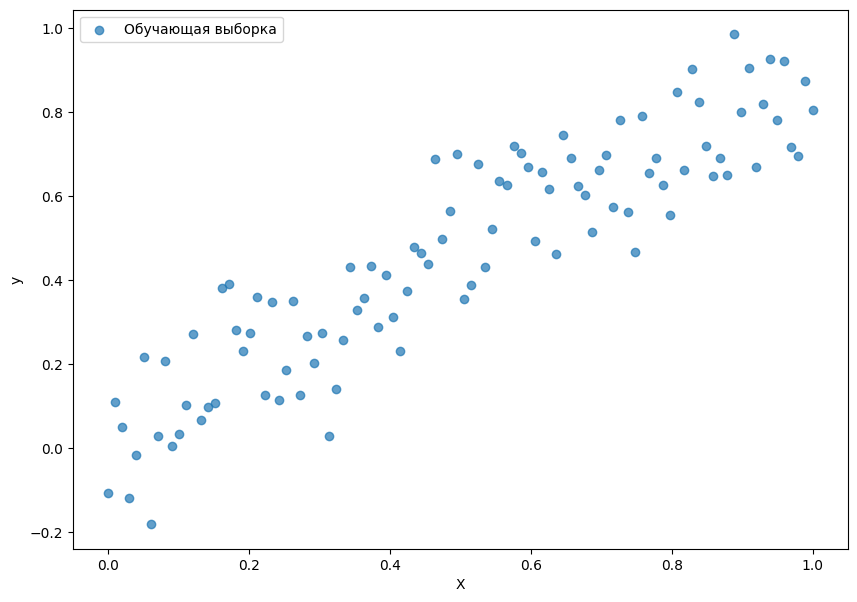

In [2]:
# Генерация выборки
np.random.seed(123)
N = 100
X = np.linspace(0, 1, N).reshape(-1, 1)
y = np.sin(X)[:, 0] + np.random.normal(0, 0.1, size = N)

# Функция для визуализации выборки и предсказаний
def plot_sample_model(X, y, plot_predictions = False, y_pred = None, y_pred_label = None, loss = 'mse'):
    plt.figure(figsize = (10, 7))
    plt.scatter(X, y, label = 'Обучающая выборка', alpha = 0.7)
    if plot_predictions:
        plt.plot(X, y_pred, label = y_pred_label, c = 'r')
        if loss == 'mse':
            plt.title('MSE: ' + str(mean_squared_error(y, y_pred)))
        elif loss == 'mae':
            plt.title('MAE: ' + str(mean_absolute_error(y, y_pred)))
    plt.xlabel('X')
    plt.ylabel('y')
    plt.legend();

plot_sample_model(X, y, plot_predictions = False)

**Шаг 0.** Имеем пустую композицию решающих деревьев $a(X) = \{\}$.

In [3]:
a = 0

**Шаг 1.** Обучим первое решающее дерево $DT_1$ и включим его в композицию: $a^{(1)}(X) = DT_1$. Получим предсказания композиции на обучающей выборке.

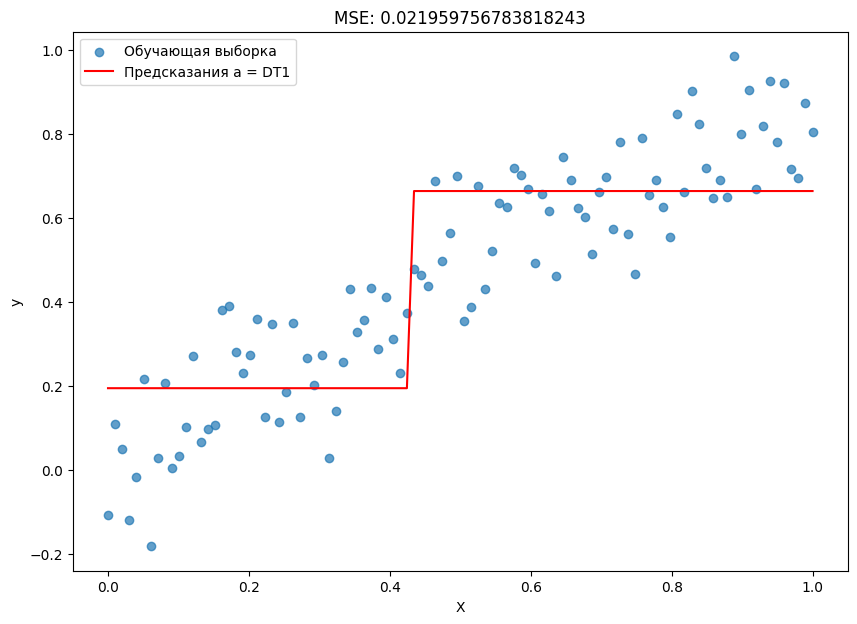

In [4]:
from sklearn.tree import DecisionTreeRegressor

# Обучим решающее дерево глубины 1 и сделаем предсказания на обучающей выборке
dt1 = DecisionTreeRegressor(max_depth = 1)
dt1.fit(X, y)
dt1_pred = dt1.predict(X)

# Включим предсказания первого дерева в композицию (простым суммированием)
a = dt1_pred.copy()

# Визуализация выборки и предсказаний
plot_sample_model(X, y, plot_predictions = True, y_pred = a, y_pred_label = 'Предсказания a = DT1')

**Шаг 2.** В качестве ошибок композиции будем использовать **остатки** –
разности между истинными ответами и предсказаниями композиции:

$$
s^{(1)}(X) = y - a^{(1)}(X)
$$

Заметим, что $MSE$ – это усредненная сумма квадратов остатков и что остатки являются естественным выражением ошибки: если мы прибавим остатки к ответам модели, то добьемся нулевой среднеквадратичной ошибки. Таким образом, логично строить следующую модель так, чтобы она хорошо предсказывала остатки композиции: если мы прибавим предсказания второй модели (предсказанные остатки) к предсказаниям первой, то добьемся снижения ошибки.

In [5]:
# Рассчитаем остатки
s1 = y - a

**Шаг 3.** Обучим второе решающее дерево $DT_2$, предсказывающее остатки. Добавим предсказания второго дерева в композицию: $a^{(2)}(X) = DT_1 + DT_2$. Получим предсказания композиции на обучающей выборке.

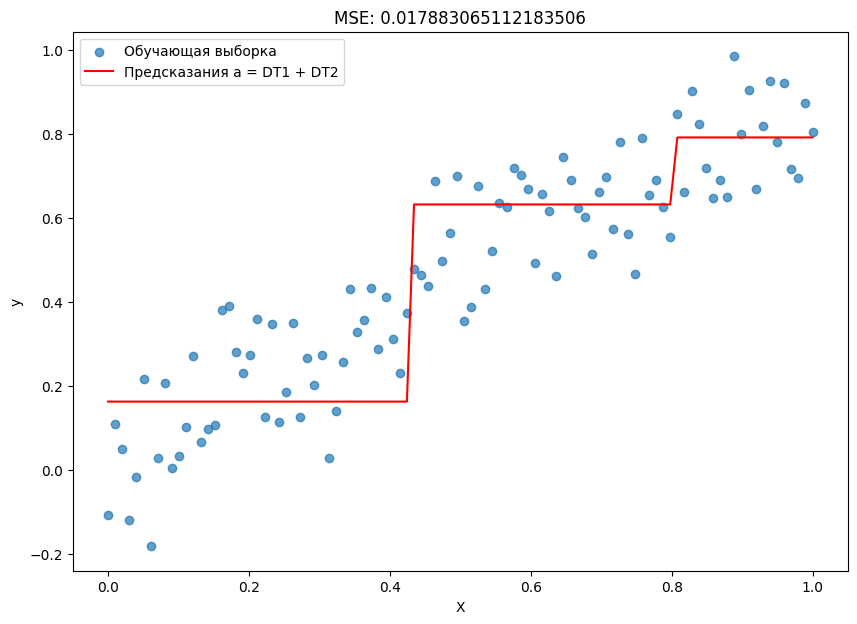

In [6]:
# Обучим второе решающее дерево глубины 1, предсказывающее остатки
dt2 = DecisionTreeRegressor(max_depth = 1)
dt2.fit(X, s1)

# Сделаем предсказания на обучающей выборке
dt2_pred = dt2.predict(X)

# Включим предсказания второго дерева в композицию (простым суммированием)
a += dt2_pred

# Визуализация выборки и предсказаний
plot_sample_model(X, y, plot_predictions = True, y_pred = a, y_pred_label = 'Предсказания a = DT1 + DT2')

Как мы видим, решающая поверхность стала более сложной, и теперь она более точно приближает обучающую выборку.

**Шаги 4 – ...** Повторяем шаги 2-3, пока не надоест.

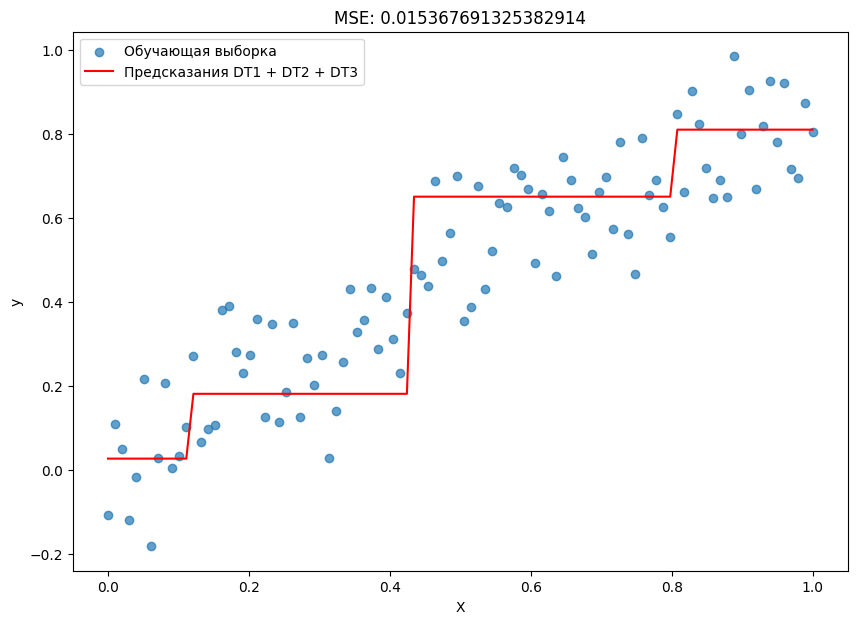

In [7]:
# Рассчитаем остатки
s2 = y - a

# Обучим третье решающее дерево глубины 1, предсказывающее остатки
dt3 = DecisionTreeRegressor(max_depth = 1)
dt3.fit(X, s2)

# Сделаем предсказания на обучающей выборке
dt3_pred = dt3.predict(X)

# Включим предсказания третьего дерева в композицию (простым суммированием)
a += dt3_pred

# Визуализация выборки и предсказаний
plot_sample_model(X, y, plot_predictions = True, y_pred = a, y_pred_label = 'Предсказания DT1 + DT2 + DT3')

Как мы видим, при добавлении базовых моделей решающая поверхность становится более сложной и все точнее приближает обучающую выборку.

**Важный момент:** заметим, что при обучении очередной базовой модели композиция предыдущего шага считается фиксированной. Это означает, что обучение новой базовой модели не влияет на уже обученные модели, содержащиеся в композиции.

### 1.2 Бустинг над разными моделями.

При помощи функции `plot_boosting_results()` визуализируем решающие поверхности композиции, очередной базовой модели и остатки при добавлении базовых моделей.

Посмотрим, как выглядят решающие поверхности композиции, если в качестве базовой модели использовать
- решающее дерево
- линейную регрессию
- kNN-регрессор
- SVR (Support Vector Regression) с линейным ядром.

Для дерева возьмем глубину 1, как и раньше.

In [8]:
def plot_boosting_results(base_estimator, n_estimators, X, y):

    fig, ax = plt.subplots(n_estimators, 3, figsize = (20, n_estimators * 4), squeeze = False)
    fig.suptitle(type(base_estimator).__name__, fontsize = 16)

    # Остатки
    resid = []
    resid.append(y)

    # Предсказания моделей
    y_pred = []

    for i in range(n_estimators):
        # Обучение очередной базовой модели
        base_estimator.fit(X, resid[-1])

        # Предсказание базовой модели
        y_pred.append(base_estimator.predict(X))

        # Вычисление предсказания композиции
        a = np.sum(y_pred, axis = 0)

        # Вычисление остатка
        resid.append(y - a)

        # Предсказания композиции
        ax[i, 0].scatter(X, y, label = 'Обучающая выборка', alpha = 0.7)
        ax[i, 0].plot(X, a, c = 'red', lw = 3, label = 'Число моделей: ' + str(i + 1))
        ax[i, 0].set_title('MSE: ' + str(mean_squared_error(y, a)))

        # Предсказания очередной модели
        ax[i, 1].scatter(X, y, label = 'Обучающая выборка', alpha = 0.7)
        ax[i, 1].plot(X, y_pred[-1], c = 'red', lw = 3)
        ax[i, 1].set_title('Предсказания модели ' + str(i + 1))

        ax[i, 2].scatter(X, resid[-1], alpha = 0.7, marker = 'v', c = 'orange')
        ax[i, 2].set_title('Остатки')

        ax[i, 0].legend()

    plt.show()

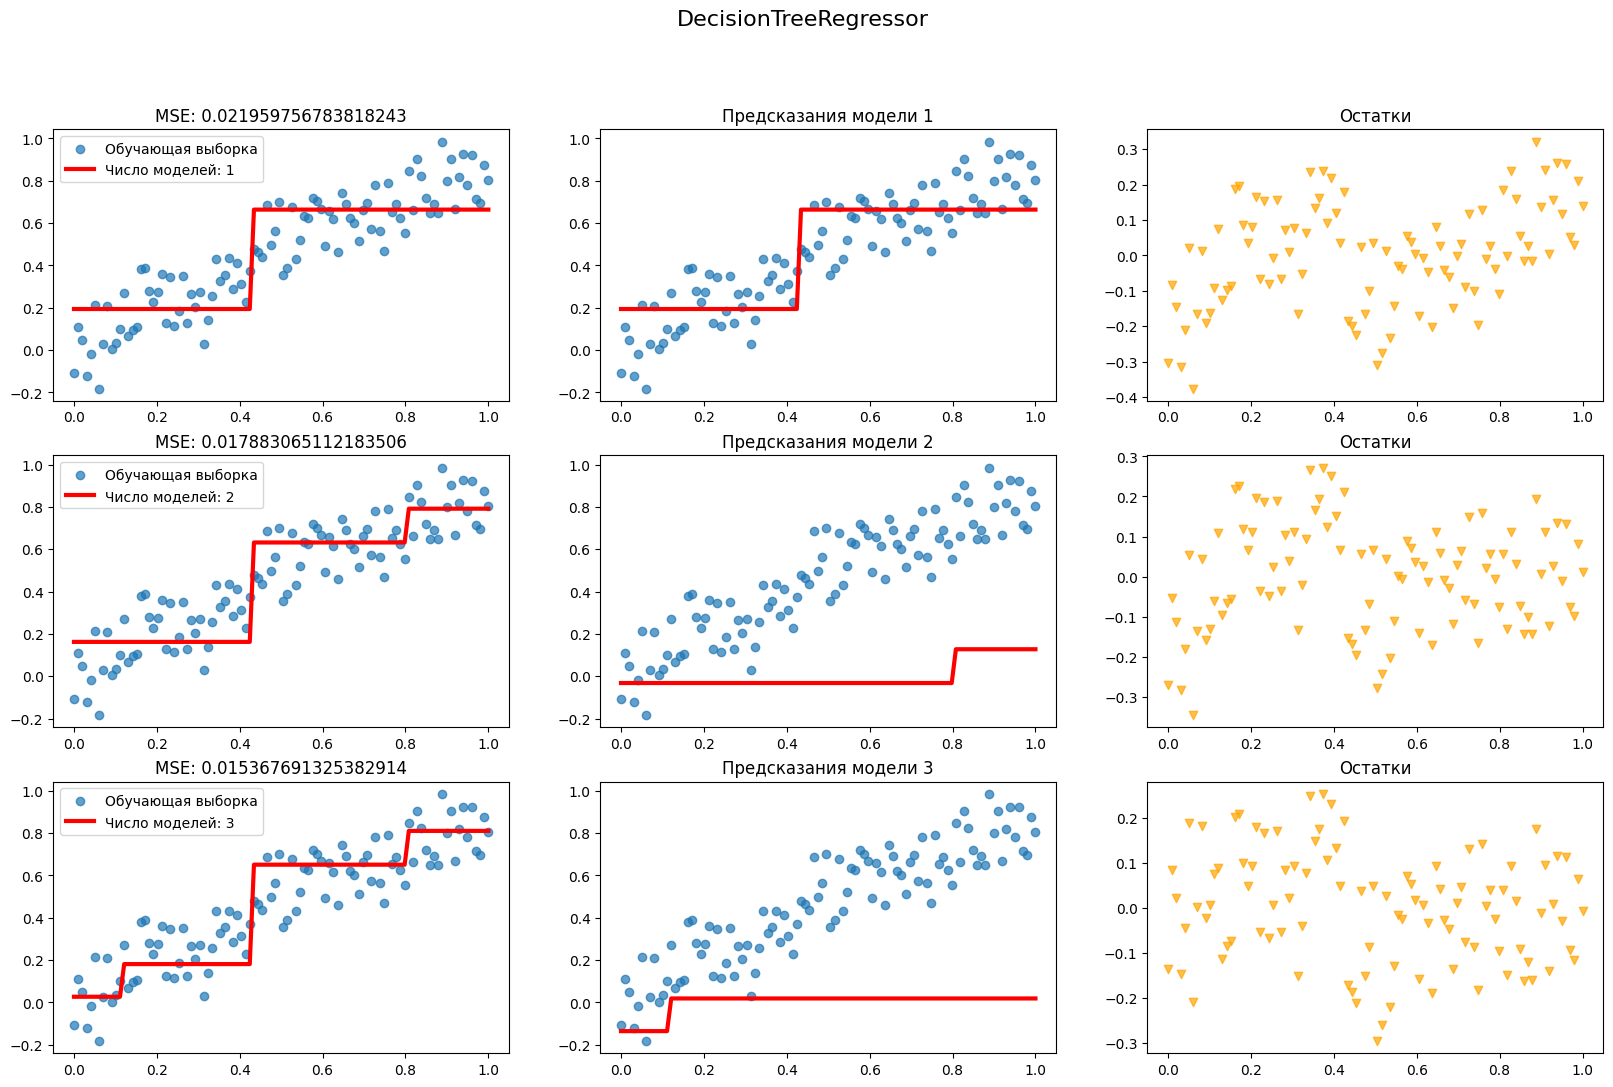

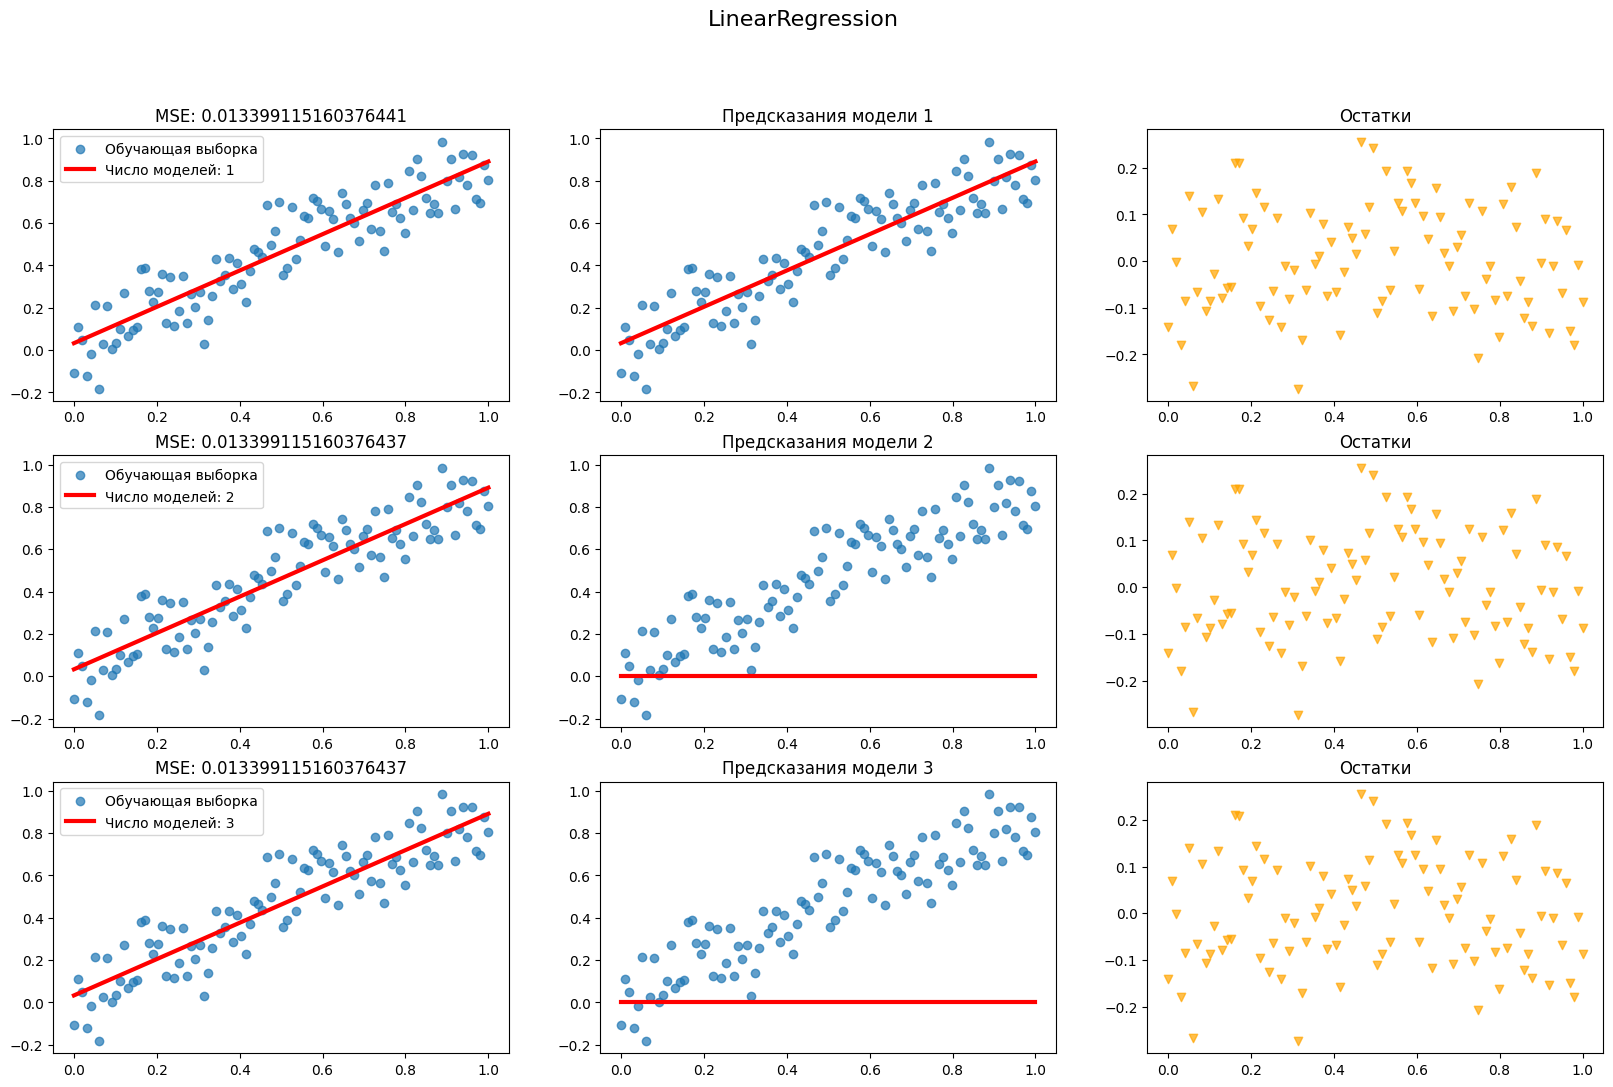

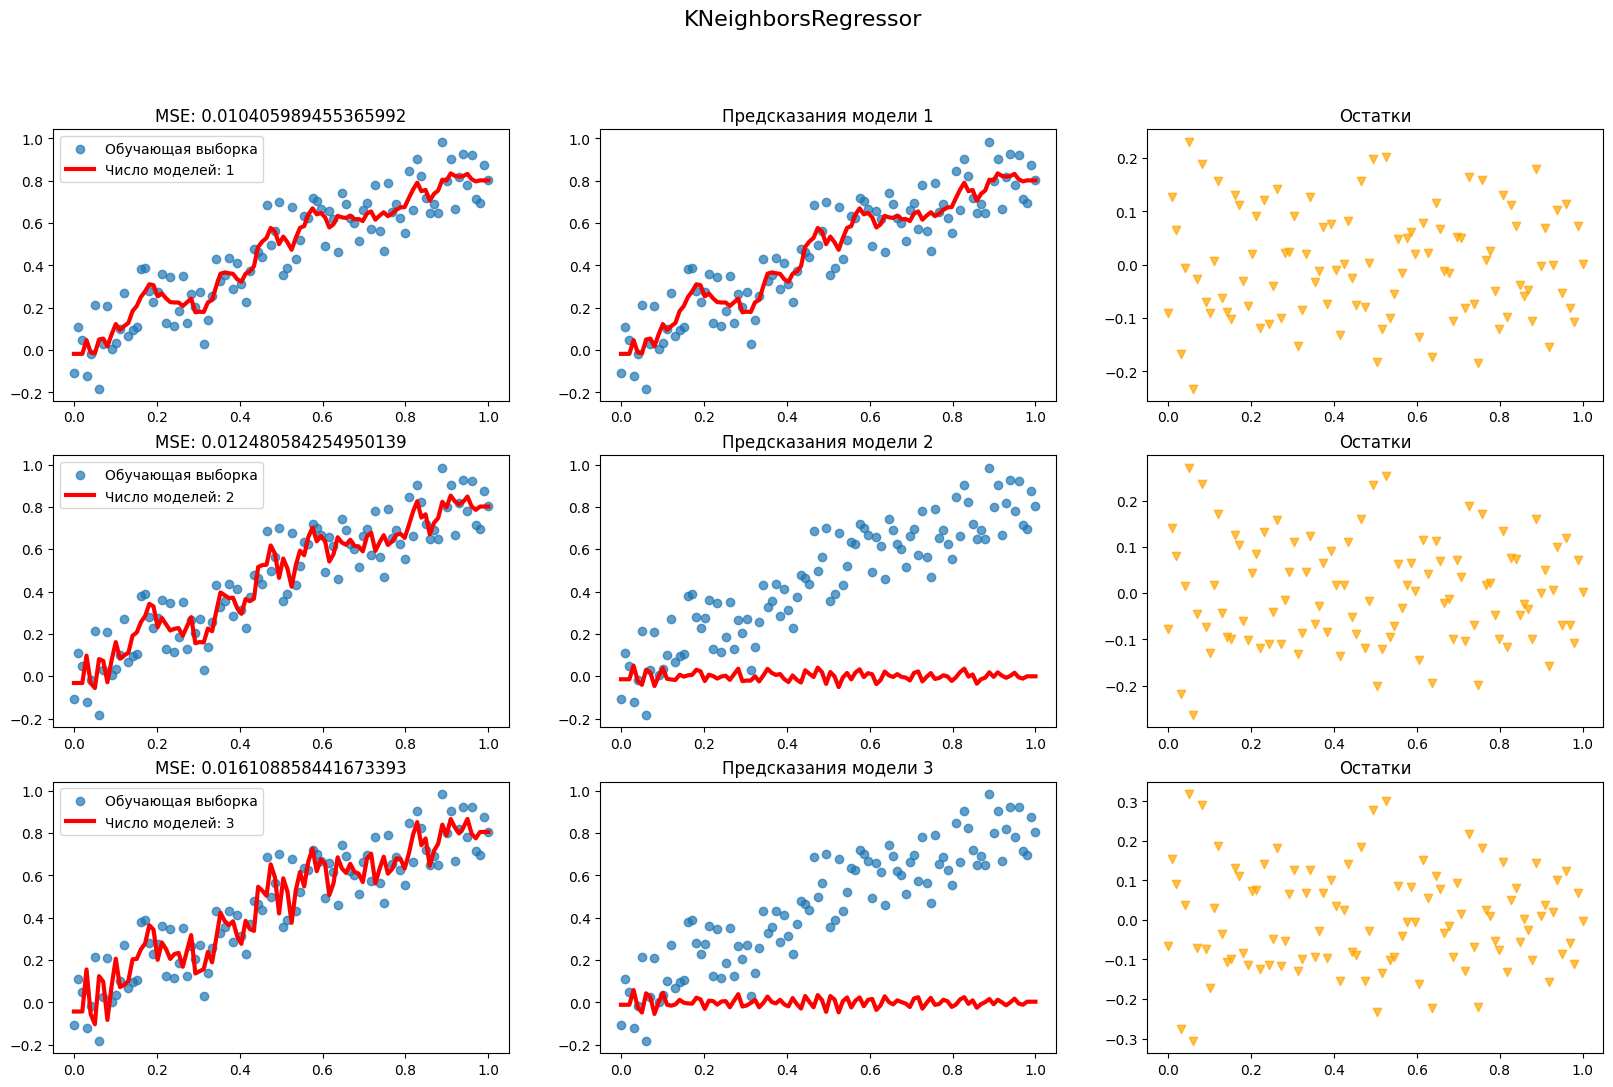

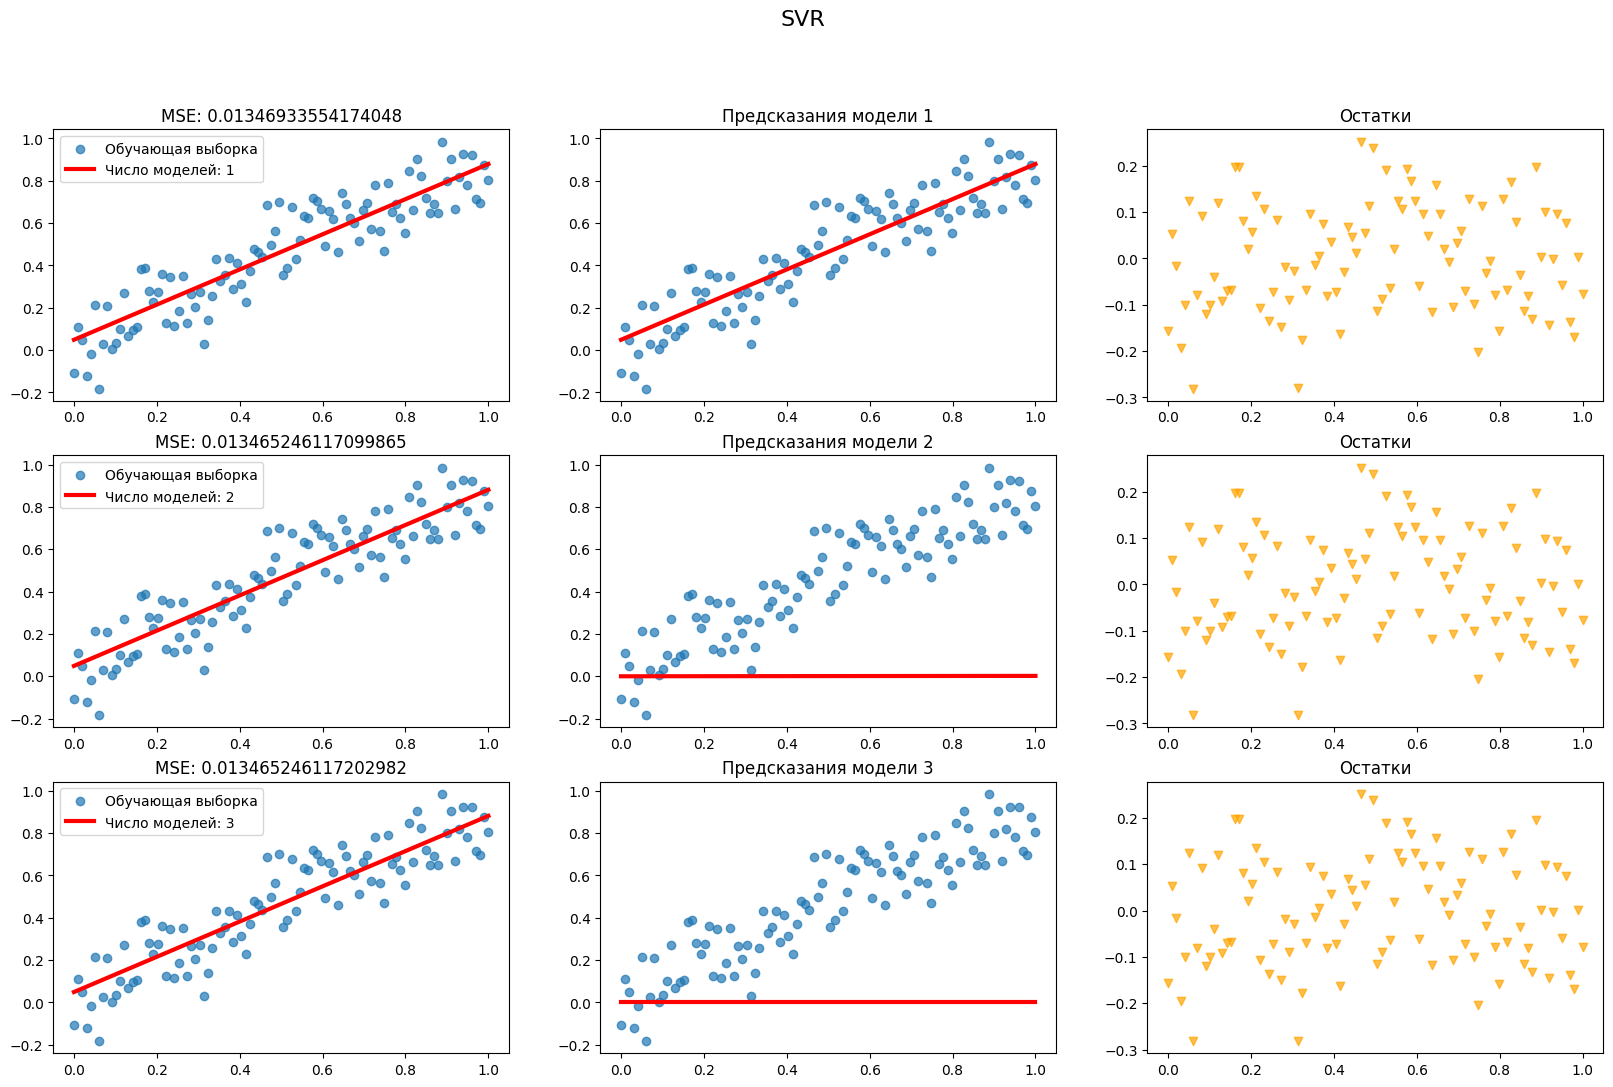

In [9]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR

for model in [DecisionTreeRegressor(max_depth = 1), LinearRegression(), KNeighborsRegressor(), SVR(kernel = 'linear')]:
    plot_boosting_results(model, n_estimators = 3, X = X, y = y)

**Что мы видим.**

- Решающий пень: каждая следующая модель улучшает композицию, $MSE$ падает.
- Линейная регрессия: после первой модели остатки уже не связаны с признаком линейно, и вторая линейная модель предсказывает ноль. Сумма линейных моделей остается линейной моделью, поэтому бустинг ничего не добавляет, $MSE$ стоит на месте.
- kNN: каждая следующая модель подгоняется под шум, и $MSE$ растет.
- SVR с линейным ядром ведет себя так же, как линейная регрессия.

Базовая модель для бустинга должна быть нелинейной, но простой. Поэтому чаще всего берут неглубокие решающие деревья.

## 2. Градиентный бустинг

Заметим, что в примере выше остатки оправданно использовались как мера ошибки: они непосредственно входят в $MSE$. Попробуем обобщить идею на произвольную функцию потерь $L(\cdot)$.

Предположим, что мы уже обучили $N-1$ базовую модель и построили композицию $a_{N-1}(X)$. Как построить $N$-ю базовую модель $b_N$?

Мы хотим выбрать $b_N$ так, чтобы как можно сильнее уменьшить ошибку:

$$
\dfrac{1}{\ell}\sum_{i = 1}^{\ell} L[y_i, a_{N-1}(x_i) + b_N(x_i)] \to \min_{b_N},
$$

где $b_N(x_i)$ – предсказания новой базовой модели. Так как и $y_i$, и $a_{N-1}(x_i)$ фиксированы (обсуждали выше), то в сущности нам нужно найти числа $b_N(x_i) = s_i^{(N)}$, которые уменьшили бы функцию потерь:

$$
\dfrac{1}{\ell}\sum_{i = 1}^{\ell} L[y_i, a_{N-1}(x_i) + s^{(N)}_i] \to \min_{s^{(N)}_i}.
$$

**Замечание.** Заметьте, что теперь мы ищем просто числа $s^{(N)}_i$, а не функцию.

После изучения градиентного спуска мы знаем, что функция быстрее всего убывает в направлении антиградиента. Поэтому в качестве чисел $s_i^{(N)}$ берем антиградиент функции потерь:

$$
s_i^{(N)} = -\dfrac{\partial L(y_i, z)}{\partial z}\bigg|_{z = a_{N-1}(x_i)},
$$

то есть антиградиент в точке ответов уже построенной композиции. Он задает только направление; насколько далеко по нему идти, мы выберем отдельно (см. раздел 4.1).

**Чек-пойнт.** Убедитесь, что вы понимаете, какие **числа** нужно взять, чтобы решить задачу.

Итак, мы выяснили, какие числа нужны для уменьшения функции потерь на **обучающей выборке**. Мы определяли их как $b_N(x_i) = s_i^{(N)}$, то есть как ответы очередной базовой модели. Значит, нужно обучить $b_N$ так, чтобы она хорошо приближала антиградиент в точке ответов композиции, а это хорошо знакомая задача обучения с учителем. Обычно она решается минимизацией $MSE$:

$$
b_N(x) = \arg\min_b \sum_{i = 1}^{\ell} (b(x_i) - s_i^{(N)})^2.
$$

**Важный момент:** задача, описанная выше, – это не изначальная задача! В этом и состоит идея градиентного бустинга: мы можем использовать любую дифференцируемую функцию потерь, через нее вывести $s_i^{(N)}$, а затем просто решать задачу приближения при помощи $MSE$.

### 2.1 Продолжение простого примера для понимания идеи.

Повторим шаги из примера 1.1, используя градиентный бустинг, чтобы лучше разобраться в идее и провести параллели. Вспомним, что мы решали задачу регрессии при помощи минимизации $MSE$.

Нулевой и первый шаги в этих примерах совпадают.

**Шаг 0.** Имеем пустую композицию решающих деревьев $a(X) = \{\}$.

In [10]:
a = 0

**Шаг 1.** Обучим первое решающее дерево $DT_1$ и включим его в композицию: $a^{(1)}(X) = DT_1$. Получим предсказания композиции на обучающей выборке.

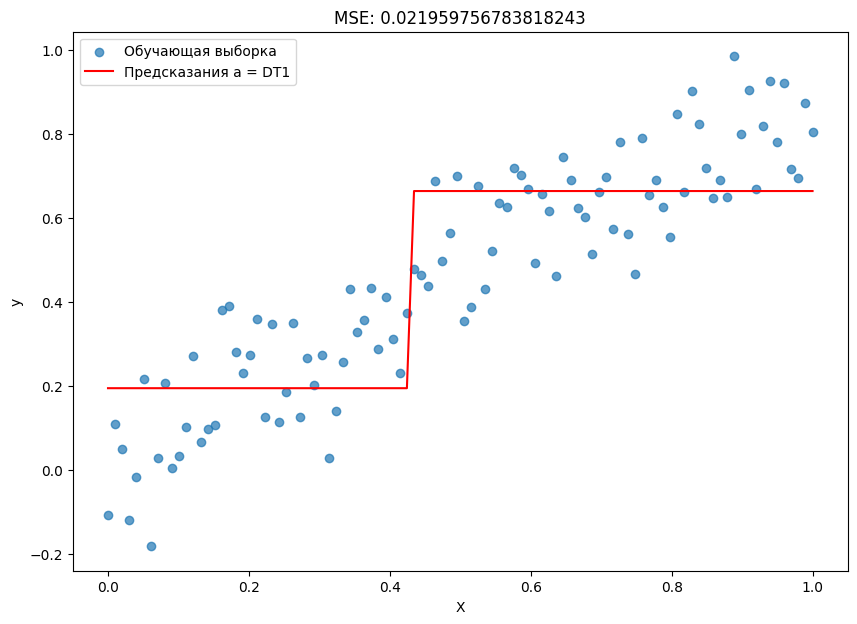

In [11]:
from sklearn.tree import DecisionTreeRegressor

# Обучим решающее дерево глубины 1 и получим предсказания на обучающей выборке
dt1 = DecisionTreeRegressor(max_depth = 1)
dt1.fit(X, y)
dt1_pred = dt1.predict(X)

# Включим предсказания первого дерева в композицию (простым суммированием)
a = dt1_pred.copy()

# Визуализация выборки и предсказаний
plot_sample_model(X, y, plot_predictions = True, y_pred = a, y_pred_label = 'Предсказания a = DT1')

**Шаг 2.** В примере 1.1 на этом шаге мы рассчитывали остатки. Здесь же мы должны рассчитать антиградиент функции потерь в точке ответов уже построенной композиции.

Вычислим градиент $MSE$

$$
L(y, p) = \dfrac{1}{2} \sum_{i = 1}^{\ell} (y_i - p_i)^2
$$

по $p_i$ в точке $p_i = a(x_i)$.



$$
\dfrac{\partial L(y, p)}{\partial p_i} = -(y_i - p_i) = \{p_i = a(x_i)\} = -(y_i - a(x_i)).
$$

Таким образом, антиградиент функции потерь равен:

$$
s_i = - (-(y_i - a(x_i))) = y_i - a(x_i),
$$

то есть в точности остаток в том виде, как мы определяли выше.

Таким образом, использование градиентного бустинга, если целевая функция – $MSE$, эквивалентно процедуре расчета остатков, как мы это делали в примере 1.1, а сами остатки совпадают с антиградиентами $s_i$!

In [12]:
# Рассчитаем антиградиент
s1 = y - a

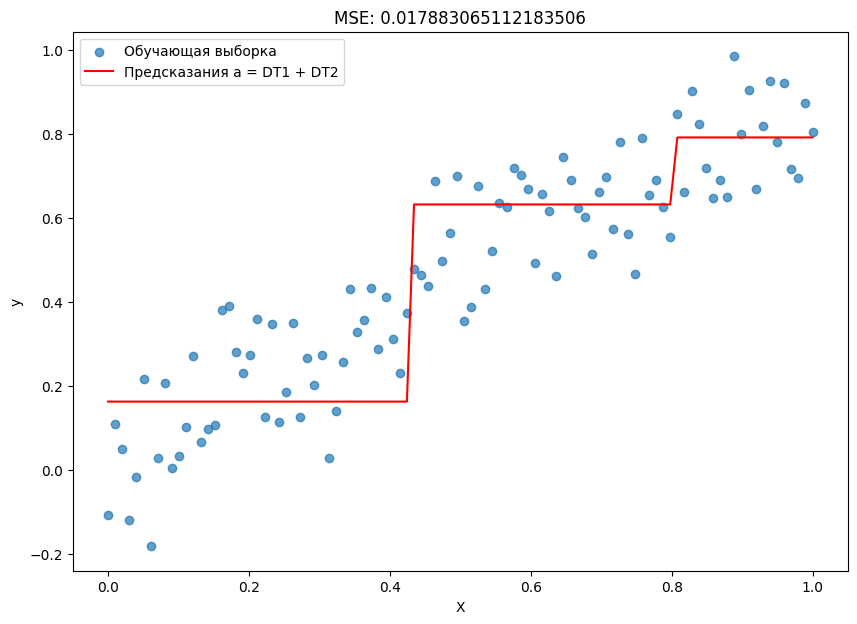

In [13]:
# Обучим второе решающее дерево глубины 1, предсказывающее антиградиент
dt2 = DecisionTreeRegressor(max_depth = 1)
dt2.fit(X, s1)

# Получим предсказания на обучающей выборке
dt2_pred = dt2.predict(X)

# Включим предсказания второго дерева в композицию (простым суммированием)
a += dt2_pred

# Визуализация выборки и предсказаний
plot_sample_model(X, y, plot_predictions = True, y_pred = a, y_pred_label = 'Предсказания a = DT1 + DT2')

**Шаг 3 и далее.** Далее нам нужно обучить базовую модель, предсказывающую $s_i$. Но так как $s_i$ совпадают с остатками, этот и дальнейшие шаги будут совпадать с примером 1.1.

## 3. Функции потерь градиентного бустинга для регрессии и классификации

### 3.1 Регрессия.

В задачах регрессии в качестве целевой функции для композиции обычно берутся:

1. $MSE$, которую мы рассматривали ранее.

2. $MAE$:

$$
MAE(y, p) = \dfrac{1}{\ell} \sum_{i = 1}^{\ell} |y_i - p_i|
$$

Попробуем сделать шаг градиентного бустинга, используя в качестве функции потерь $MAE$.

**Задание:** рассчитайте $s_i^{(N)}$ для $MAE$.

**Решение:** $s_i^{(N)} = -\mathrm{sign}(a_{N-1}(x_i) - y_i) = \mathrm{sign}(y_i - a_{N-1}(x_i))$.

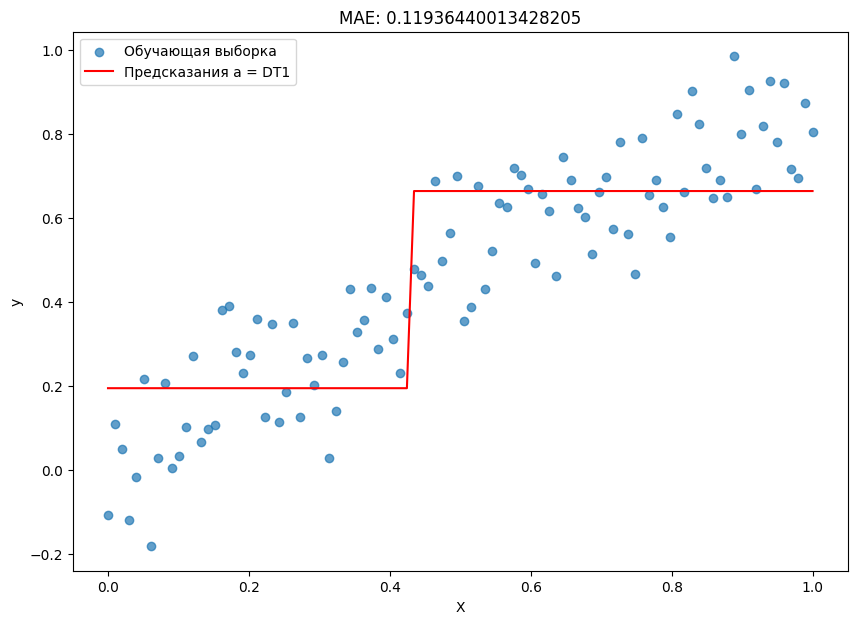

In [14]:
# Инициализация
a = 0

# Обучим решающее дерево глубины 1 и получим предсказания на обучающей выборке
dt1 = DecisionTreeRegressor(max_depth = 1)
dt1.fit(X, y)
dt1_pred = dt1.predict(X)

# Включим предсказания первого дерева в композицию (простым суммированием)
a = dt1_pred.copy()

# Визуализация выборки и предсказаний
plot_sample_model(X, y, plot_predictions = True, y_pred = a, y_pred_label = 'Предсказания a = DT1', loss = 'mae')

In [15]:
# Рассчитаем антиградиент
s1 = -np.sign(a - y)

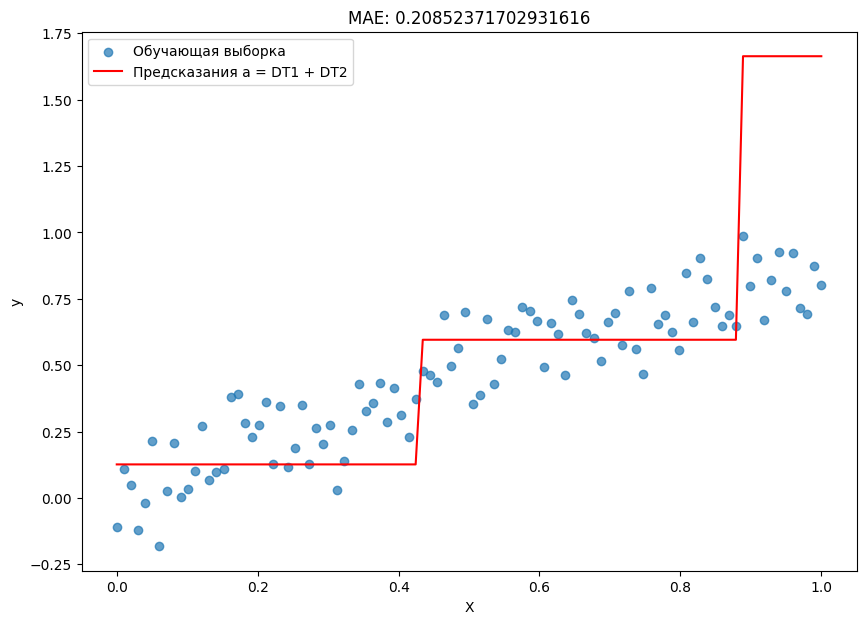

In [16]:
# Обучим второе решающее дерево глубины 1, предсказывающее антиградиент
dt2 = DecisionTreeRegressor(max_depth = 1)
dt2.fit(X, s1)

# Получим предсказания на обучающей выборке
dt2_pred = dt2.predict(X)

# Включим предсказания второго дерева в композицию (простым суммированием)
a += dt2_pred

# Визуализация выборки и предсказаний
plot_sample_model(X, y, plot_predictions = True, y_pred = a,
                  y_pred_label = 'Предсказания a = DT1 + DT2', loss = 'mae')

Заметим, что $MAE$ увеличилась, а предсказания композиции на правом краю выходят далеко за пределы обучающей выборки. Причина: антиградиент $MAE$ равен $\pm 1$ независимо от размера ошибки, а дерево предсказывает средние значения этих знаков, то есть числа порядка единицы, тогда как сами ошибки порядка $0.1$. Шаг получился слишком большим. Проблема решается подбором длины шага, см. раздел 4.1.

### 3.2 Классификация.

В задачах бинарной классификации обычно используется логистическая функция потерь, с которой мы уже сталкивались в логистической регрессии.

$$
L(y, p) = \log(1 + e^{-yp}).
$$

Покажем, что в этом случае (метки $y_i \in \{-1, +1\}$, а $a_{N-1}(x_i)$ – произвольное число) антиградиенты можно вычислить по формуле

$$
s^{(N)}_i = \dfrac{y_i}{1 + e^{y_i a_{N-1}(x_i)}}.
$$

Действительно,

$$
-\dfrac{\partial}{\partial z}\log(1 + e^{-yz}) = \dfrac{y e^{-yz}}{1 + e^{-yz}} = \dfrac{y}{1 + e^{yz}}, \quad z = a_{N-1}(x_i).
$$

**Важно:** ответ композиции $a(x)$ здесь – не вероятность, а логит (число на всей прямой). Вероятность класса $+1$ равна $\sigma(a(x)) = \dfrac{1}{1 + e^{-a(x)}}$. Метки должны быть именно $-1$ и $+1$: для метки $0$ формула потери теряет смысл.

Попробуем сделать два шага градиентного бустинга в задаче бинарной классификации с логистической функцией потерь. Возьмем два класса ирисов, versicolor и virginica: одним порогом на одном признаке они не разделяются.

In [17]:
from sklearn.datasets import load_iris

# Загрузка данных
data = load_iris()

# Оставляем два класса (versicolor и virginica) и кодируем метки как -1 и +1
mask = data['target'] > 0
X = data['data'][mask]
y = np.where(data['target'][mask] == 2, 1, -1)
set(y)

{np.int64(-1), np.int64(1)}

In [18]:
# Инициализация
a = 0

# Обучение решающего дерева глубины 1 и получение предсказаний на обучающей выборке
dt1 = DecisionTreeRegressor(max_depth = 1)
dt1.fit(X, y)
dt1_pred = dt1.predict(X)

# Включение предсказаний первого дерева в композицию (простым суммированием)
a = dt1_pred.copy()

In [19]:
def logistic_loss(y, y_pred):
    # Логистическая функция потерь (метки -1 и +1)
    return np.log(1 + np.exp(- y * y_pred)).mean()

In [20]:
# Вычисление ошибки для одного дерева
print('Логистическая потеря:', logistic_loss(y, a))
print('Число ошибок классификации:', (np.sign(a) != y).sum())

Логистическая потеря: 0.397798024027951
Число ошибок классификации: 6


In [21]:
# Рассчитаем антиградиент
s1 = y / (1 + np.exp(y * a))

# Объекты, на которых композиция ошибается, получают больший по модулю антиградиент
wrong = np.sign(a) != y
print('Средний |s| на ошибочных объектах:', np.abs(s1[wrong]).mean())
print('Средний |s| на остальных объектах:', np.abs(s1[~wrong]).mean())

Средний |s| на ошибочных объектах: 0.6980162782145637
Средний |s| на остальных объектах: 0.29284348721491227


In [22]:
# Обучим второе решающее дерево глубины 1, предсказывающее антиградиент
dt2 = DecisionTreeRegressor(max_depth = 1)
dt2.fit(X, s1)

# Получим предсказания на обучающей выборке
dt2_pred = dt2.predict(X)

# Включим предсказания второго дерева в композицию (простым суммированием)
a += dt2_pred

In [23]:
# Вычислим ошибки для двух деревьев
print('Логистическая потеря:', logistic_loss(y, a))
print('Число ошибок классификации:', (np.sign(a) != y).sum())

Логистическая потеря: 0.333354682583603
Число ошибок классификации: 6


Логистическая потеря уменьшилась, а число ошибок осталось прежним. Бустинг минимизирует функцию потерь, а не число ошибок: композиция становится увереннее на объектах, которые уже классифицируются верно, и это тоже уменьшает потерю.

## 4. Особенности градиентного бустинга

### 4.1 Построение композиции.

В примерах выше мы строили композицию моделей простым суммированием. Понятно, что в общем виде можно строить взвешенную сумму базовых моделей:

$$
a(X) = \sum_{n = 1}^{k} w_nb_n(X),
$$

где коэффициенты $w_n$ можно подобрать, например, при помощи градиентного спуска в задаче

$$
w_n = \arg\min_{w} \sum_{i = 1}^{\ell} L(y_i, a^{(N-1)}(x_i) + w \times b_N(x_i)),
$$

что имеет смысл, так как $b_N(x_i)$ уже обучена и фиксирована.

**Замечание:** длина шага является одним из ключевых параметров градиентного бустинга, и может очень сильно повлиять на его производительность. Подробнее об этом можно почитать, например, [здесь](https://machinelearningmastery.com/tune-learning-rate-for-gradient-boosting-with-xgboost-in-python/).

В нашем случае подбор правильного коэффициента поможет решить увеличение MAE в примере 3.1.

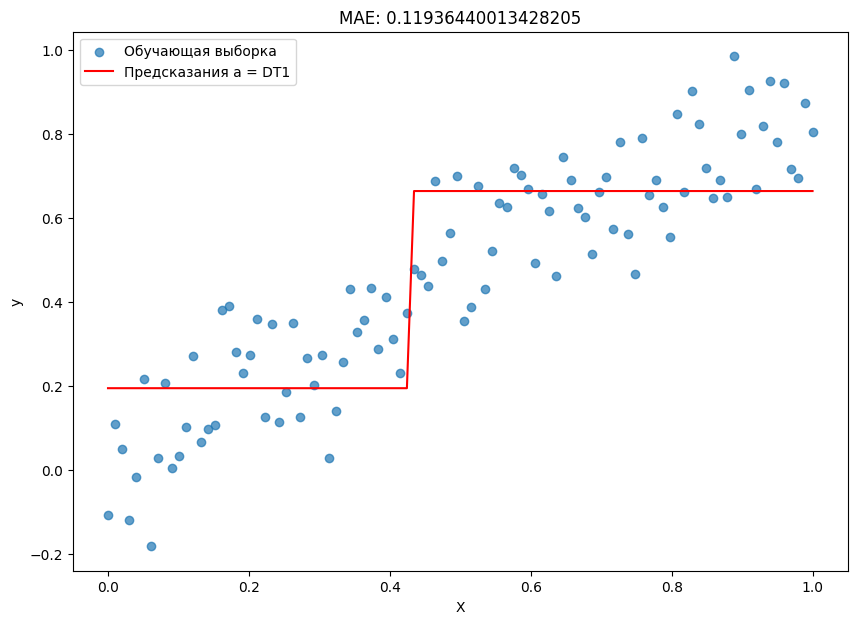

In [24]:
# Инициализация
np.random.seed(123)
N = 100
X = np.linspace(0, 1, N).reshape(-1, 1)
y = np.sin(X)[:, 0] + np.random.normal(0, 0.1, size = N)
a = 0

# Обучим решающее дерево глубины 1 и получим предсказания на обучающей выборке
dt1 = DecisionTreeRegressor(max_depth = 1)
dt1.fit(X, y)
dt1_pred = dt1.predict(X)

# Включим предсказания первого дерева в композицию (простым суммированием)
a = dt1_pred.copy()

# Визуализация выборки и предсказаний
plot_sample_model(X, y, plot_predictions = True, y_pred = a, y_pred_label = 'Предсказания a = DT1', loss = 'mae')

In [25]:
# Вычислим антиградиент
s1 = -np.sign(a - y)

In [26]:
# Обучим второе дерево на антиградиенте и посмотрим, как MAE зависит от веса w
dt2 = DecisionTreeRegressor(max_depth = 1)
dt2.fit(X, s1)
dt2_pred = dt2.predict(X)

print('MAE до добавления второго дерева:', round(mean_absolute_error(y, a), 4))
for w in [0.05, 0.1, 0.2, 0.3, 0.5, 1]:
    print(f'w = {w:<4}  MAE = {mean_absolute_error(y, a + w * dt2_pred):.4f}')

MAE до добавления второго дерева: 0.1194
w = 0.05  MAE = 0.1145
w = 0.1   MAE = 0.1114
w = 0.2   MAE = 0.1107
w = 0.3   MAE = 0.1178
w = 0.5   MAE = 0.1425
w = 1     MAE = 0.2085


In [27]:
# Берем вес с наименьшей MAE из перебора выше
w = 0.2

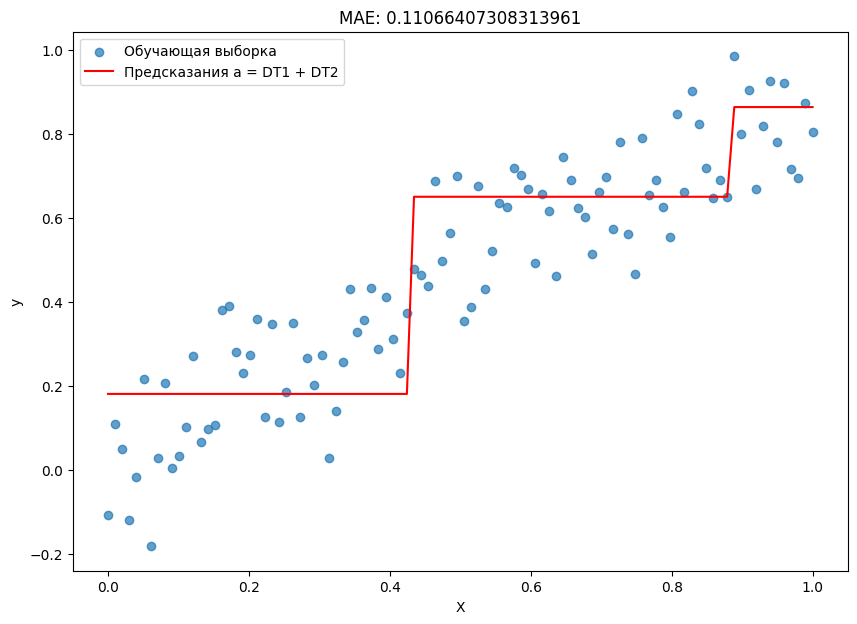

In [28]:
# Обучим второе решающее дерево глубины 1, предсказывающее антиградиент
dt2 = DecisionTreeRegressor(max_depth = 1)
dt2.fit(X, s1)

# Получим предсказания на обучающей выборке
dt2_pred = dt2.predict(X)

# Включим предсказания второго дерева в композицию (простым суммированием)
a += w * dt2_pred

# Визуализация выборки и предсказаний
plot_sample_model(X, y, plot_predictions = True, y_pred = a,
                  y_pred_label = 'Предсказания a = DT1 + DT2', loss = 'mae')

### 4.2 Переобучение.

Вспомним, что в случае бэггинга увеличение числа базовых моделей не приводило к переобучению. Например, в случайном лесе ошибки на тренировочной и тестовой выборках выходили на плато, начиная с какого-то числа деревьев. Понятно, что бустинг не будет обладать этим свойством *по построению*: при добавлении новых базовых моделей композиция все точнее будет приближать обучающую выборку, что в конечном итоге (зачастую быстро) может привести к переобучению. Из этого можно сделать вывод, что в случае бустинга ошибка на обучающей выборке в зависимости от числа деревьев является убывающей функцией, а ошибка на тестовой выборке, скорее всего, имеет U-образный вид. Убедимся в этом и сравним поведение ошибок и решающих поверхностей бустинга и случайного леса.

Будем использовать [реализацию бустинга](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.GradientBoostingRegressor.html) из `sklearn`, которая представляет собой градиентный бустинг над деревьями.

In [29]:
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor

In [30]:
# Генерация выборки
np.random.seed(123)
X = np.linspace(0, 1, 300).reshape(-1, 1)

def target(a):
    return a > 0.5

y = target(X) + np.random.normal(size = X.shape) * 0.1
y = y[:, 0]

In [31]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = 123)

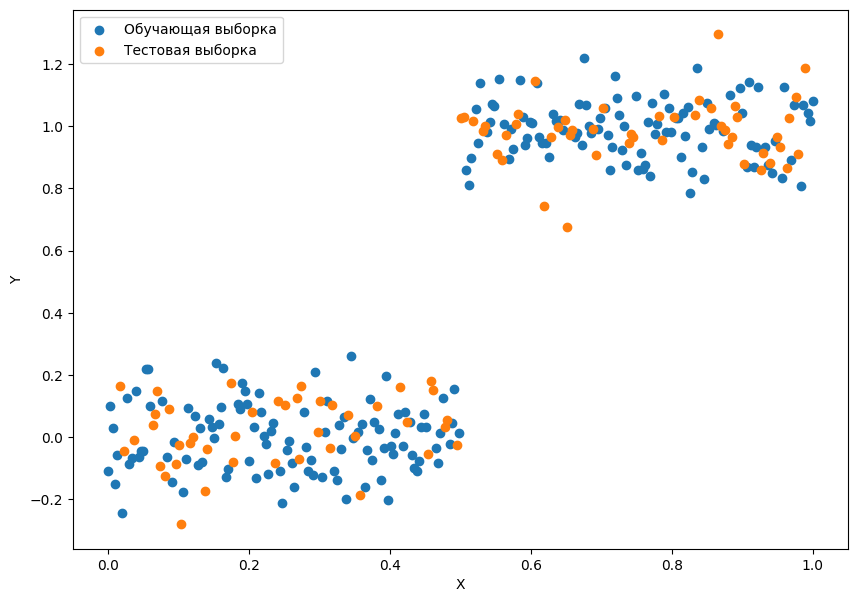

In [32]:
# Визуализация выборки
plt.figure(figsize = (10, 7))
plt.scatter(X_train, y_train, label = 'Обучающая выборка')
plt.scatter(X_test, y_test, label = 'Тестовая выборка')
plt.xlabel('X')
plt.ylabel('Y')
plt.legend();

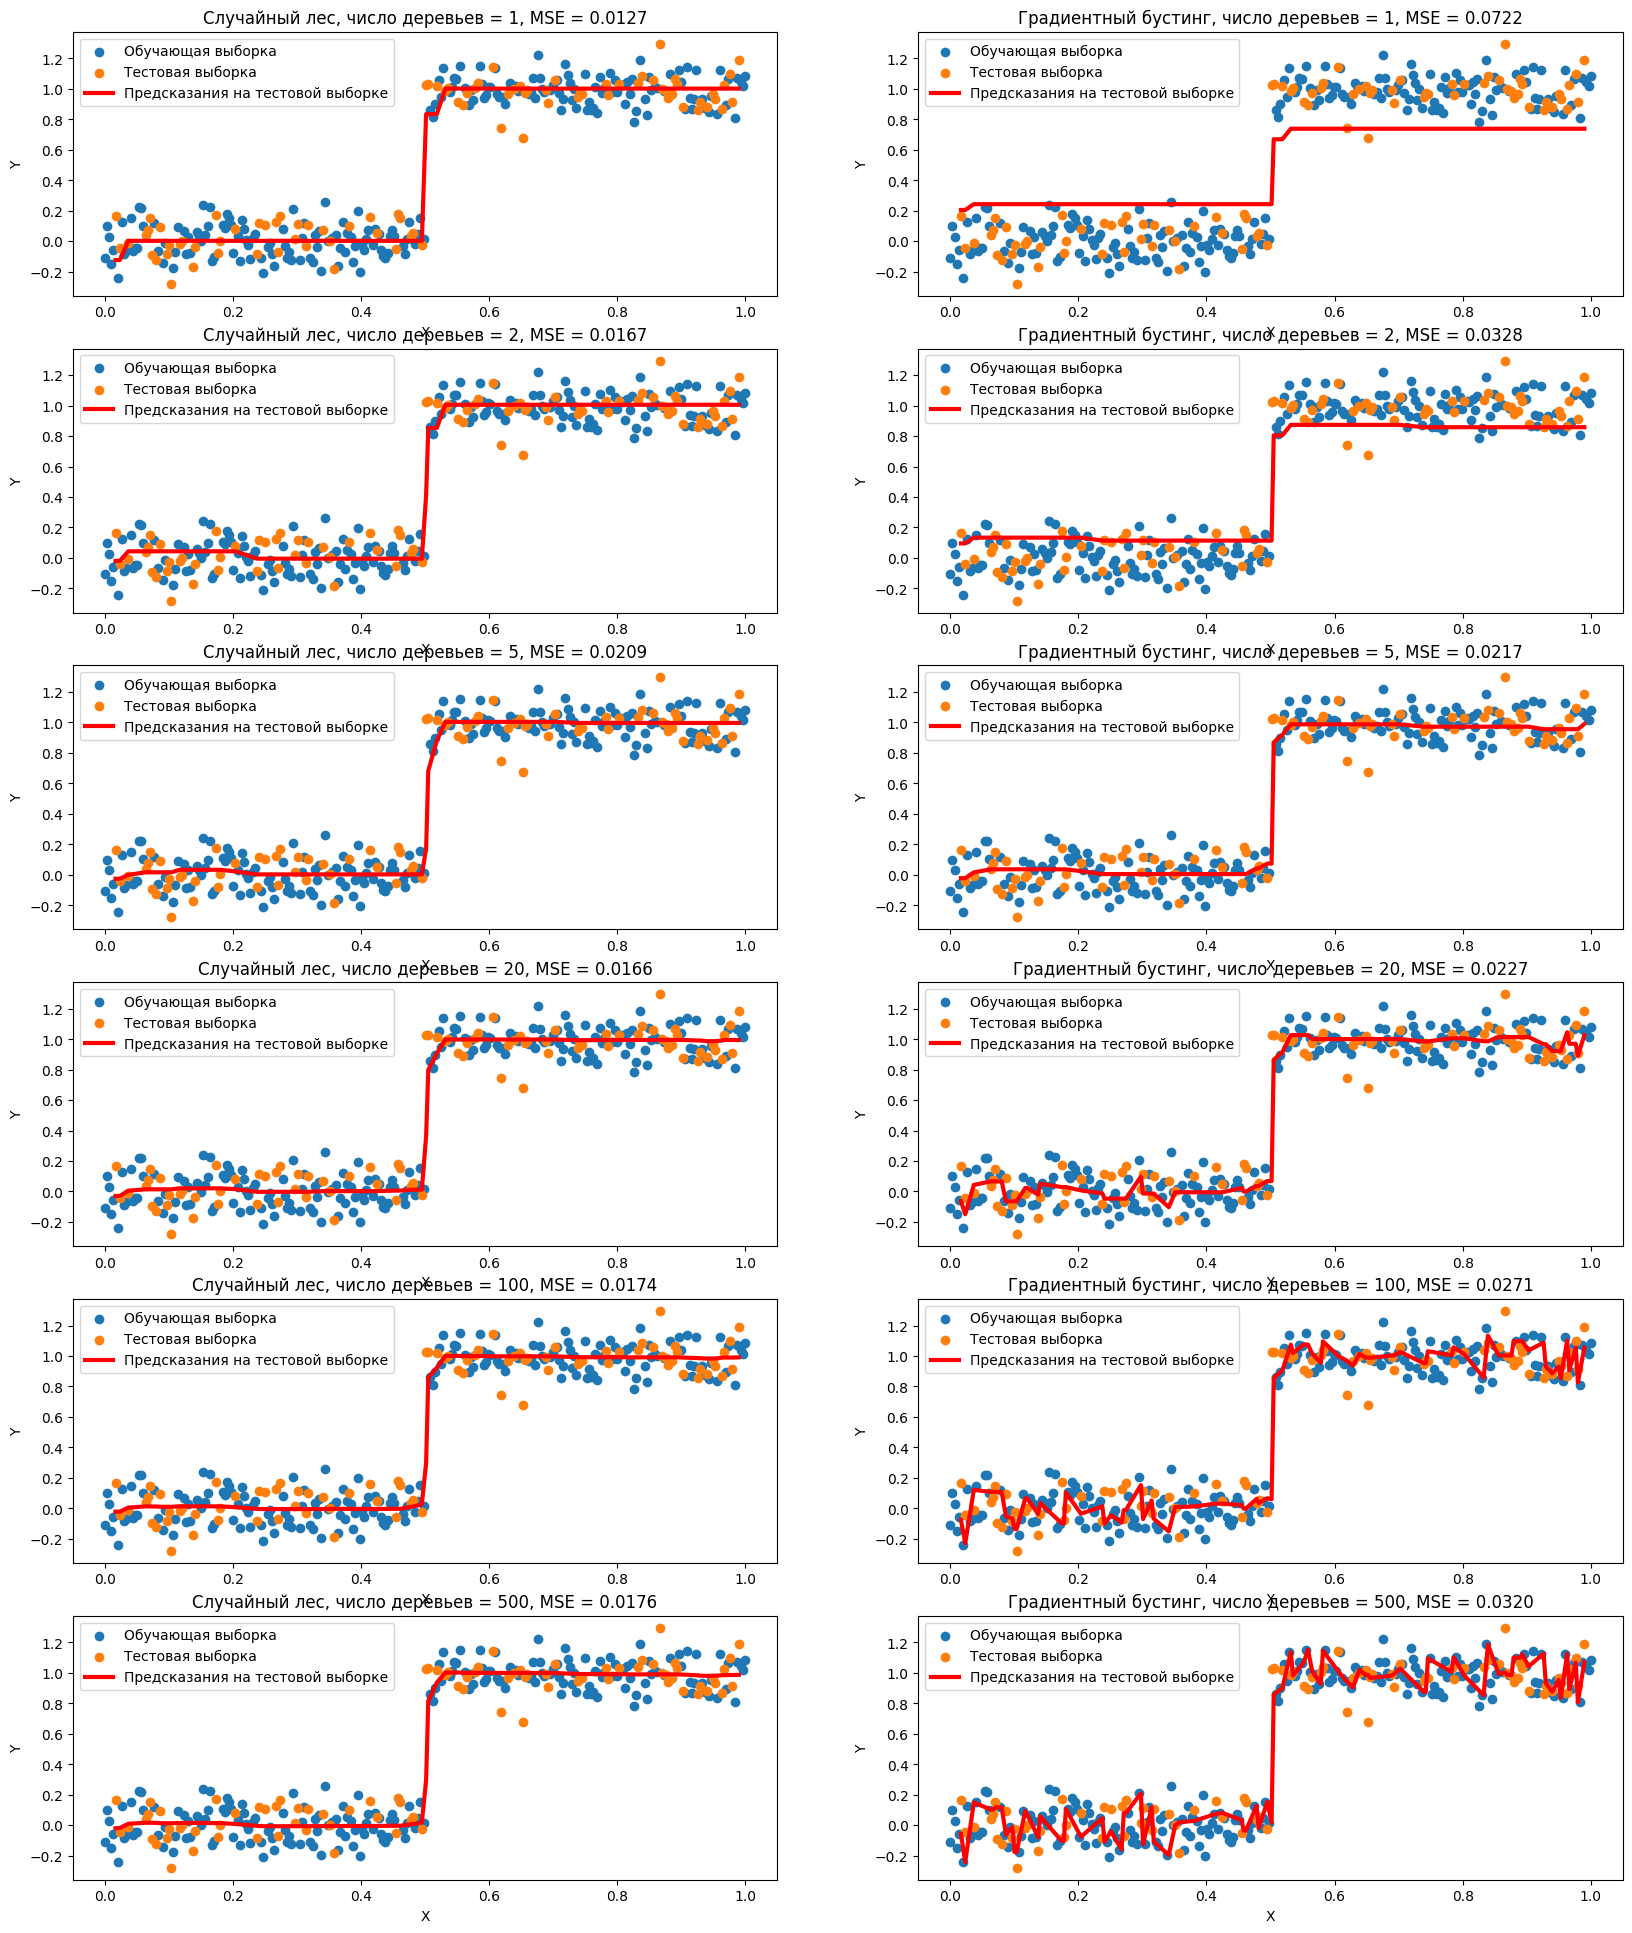

In [33]:
# Визуализация решающих поверхностей
trees = [1, 2, 5, 20, 100, 500]

fig, ax = plt.subplots(len(trees), 2, figsize = (20, 4 * len(trees)))

for i, ts in enumerate(trees):
    rf = RandomForestRegressor(n_estimators = ts, max_depth = 2, random_state = 123)
    gb = GradientBoostingRegressor(n_estimators = ts, max_depth = 2, learning_rate = 0.5, random_state = 123)

    for j, (model, name) in enumerate([(rf, 'Случайный лес'), (gb, 'Градиентный бустинг')]):
        model.fit(X_train, y_train)
        X_sorted = np.sort(X_test, axis = 0)
        ax[i, j].scatter(X_train, y_train, label = 'Обучающая выборка')
        ax[i, j].scatter(X_test, y_test, label = 'Тестовая выборка')
        ax[i, j].plot(X_sorted, model.predict(X_sorted), lw = 3, c = 'red', label = 'Предсказания на тестовой выборке')
        ax[i, j].set_xlabel('X')
        ax[i, j].set_ylabel('Y')
        ax[i, j].set_title(f'{name}, число деревьев = {ts}, MSE = {mean_squared_error(y_test, model.predict(X_test)):.4f}')
        ax[i, j].legend()

Решающая поверхность случайного леса почти не меняется после нескольких деревьев. У бустинга она сначала приближает ступеньку, а при большом числе деревьев начинает повторять шум обучающей выборки.

Бустинг: минимум тестовой MSE 0.0217 при 5 деревьях, при 1000 деревьях 0.0322


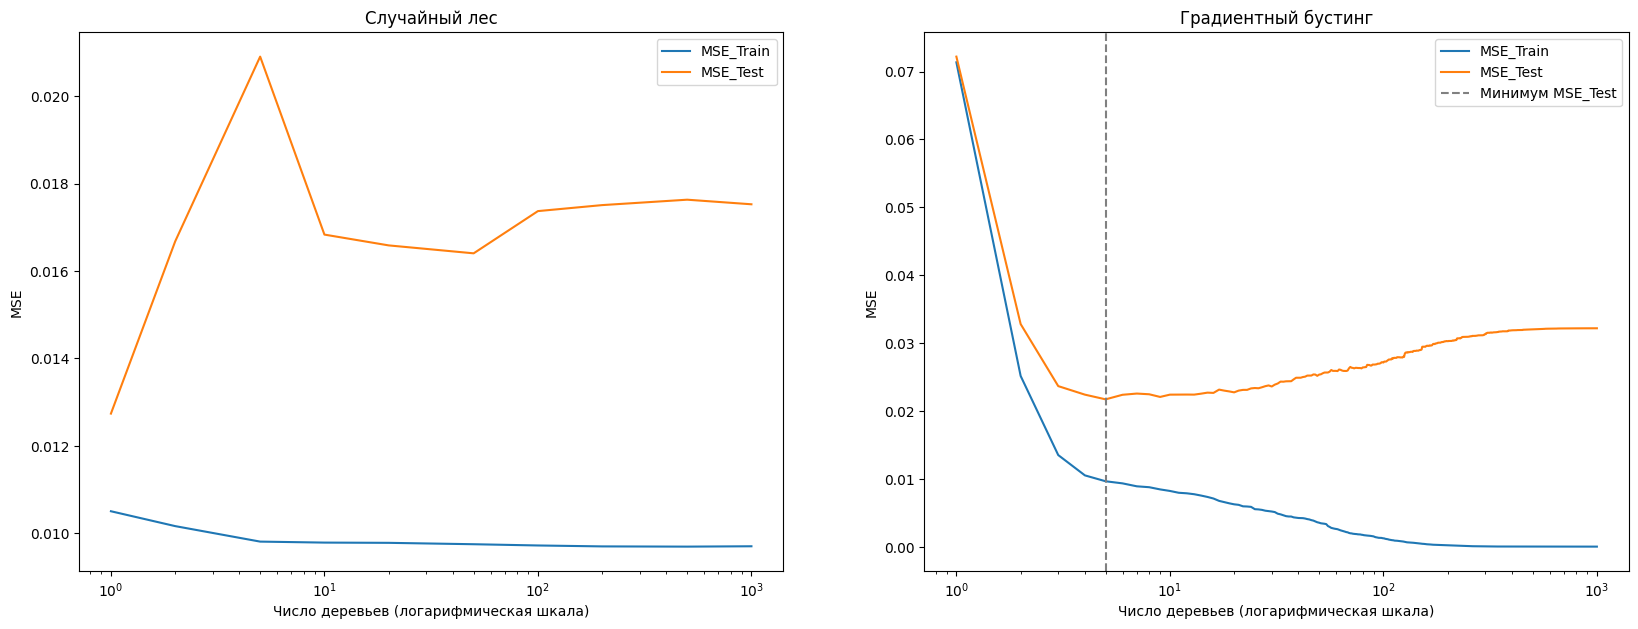

In [34]:
# Бустинг: ошибки после каждого из 1000 деревьев (staged_predict возвращает предсказания композиции после каждого дерева)
n_max = 1000
gb = GradientBoostingRegressor(n_estimators = n_max, max_depth = 2, learning_rate = 0.5, random_state = 123).fit(X_train, y_train)
loss_gb_train = [mean_squared_error(y_train, p) for p in gb.staged_predict(X_train)]
loss_gb_test = [mean_squared_error(y_test, p) for p in gb.staged_predict(X_test)]

# Случайный лес: обучаем отдельно для каждого числа деревьев
trees_rf = [1, 2, 5, 10, 20, 50, 100, 200, 500, 1000]
loss_rf_train, loss_rf_test = [], []
for ts in trees_rf:
    rf = RandomForestRegressor(n_estimators = ts, max_depth = 2, random_state = 123).fit(X_train, y_train)
    loss_rf_train.append(mean_squared_error(y_train, rf.predict(X_train)))
    loss_rf_test.append(mean_squared_error(y_test, rf.predict(X_test)))

fig, ax = plt.subplots(1, 2, figsize = (20, 7))

ax[0].plot(trees_rf, loss_rf_train, label = 'MSE_Train')
ax[0].plot(trees_rf, loss_rf_test, label = 'MSE_Test')
ax[0].set_title('Случайный лес')

ax[1].plot(range(1, n_max + 1), loss_gb_train, label = 'MSE_Train')
ax[1].plot(range(1, n_max + 1), loss_gb_test, label = 'MSE_Test')
ax[1].axvline(np.argmin(loss_gb_test) + 1, color = 'gray', ls = '--', label = 'Минимум MSE_Test')
ax[1].set_title('Градиентный бустинг')

for a_ in ax:
    a_.set_xscale('log')
    a_.set_xlabel('Число деревьев (логарифмическая шкала)')
    a_.set_ylabel('MSE')
    a_.legend()

print(f'Бустинг: минимум тестовой MSE {min(loss_gb_test):.4f} при {np.argmin(loss_gb_test) + 1} деревьях, при {n_max} деревьях {loss_gb_test[-1]:.4f}')

Поведение случайного леса такое же, как на предыдущем семинаре: после нескольких деревьев ошибки практически не меняются. У бустинга картина другая: ошибка на обучающей выборке стабильно убывает почти до нуля, а ошибка на тестовой выборке сначала падает, достигает минимума при небольшом числе деревьев и затем растет: композиция начинает подгоняться под шум. Это типичная U-образная кривая.

Как быстро наступает переобучение, зависит от параметров. При глубине 1 и темпе 0.1 оно было бы медленным, а при глубине 2 и темпе 0.5, как здесь, наступает почти сразу.

Основные способы регуляризации бустинга:

1. **Сокращение шага.** Новая модель добавляется с коэффициентом:

$$
a_N(X) = a_{N-1}(X) + \alpha w_N b_N(X),
$$

где $\alpha \in (0, 1]$ – темп обучения.

2. **Выбор числа деревьев по валидации** (ранняя остановка).

3. **Стохастический градиентный бустинг:** каждое дерево обучается на случайной подвыборке объектов (параметр `subsample`).

4. **Ограничение сложности базовых моделей:** глубина, число листьев, минимальное число объектов в листе.

Проверим первый способ.

learning_rate = 0.5: минимум 0.0217 при 5 деревьях, при 1000 деревьях 0.0322
learning_rate = 0.1: минимум 0.0218 при 31 деревьях, при 1000 деревьях 0.0293
learning_rate = 0.02: минимум 0.0218 при 175 деревьях, при 1000 деревьях 0.0235


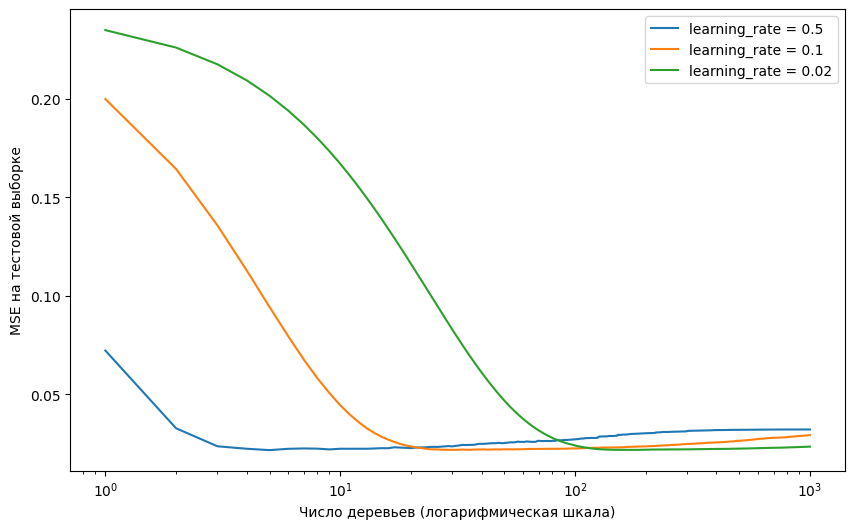

In [35]:
# Темп обучения: чем он меньше, тем медленнее растет тестовая ошибка после минимума
fig, ax = plt.subplots(figsize = (10, 6))

for lr in [0.5, 0.1, 0.02]:
    g = GradientBoostingRegressor(n_estimators = 1000, max_depth = 2, learning_rate = lr, random_state = 123).fit(X_train, y_train)
    test_loss = [mean_squared_error(y_test, p) for p in g.staged_predict(X_test)]
    ax.plot(range(1, 1001), test_loss, label = f'learning_rate = {lr}')
    print(f'learning_rate = {lr}: минимум {min(test_loss):.4f} при {np.argmin(test_loss) + 1} деревьях, при 1000 деревьях {test_loss[-1]:.4f}')

ax.set_xscale('log')
ax.set_xlabel('Число деревьев (логарифмическая шкала)')
ax.set_ylabel('MSE на тестовой выборке')
ax.legend();

Минимум почти одинаковый, но с маленьким темпом он достигается за большее число деревьев, а после него ошибка растет медленнее. Это цена за аккуратность: меньше темп, больше деревьев.

Второй способ: не перебирать число деревьев вручную, а остановить обучение, когда ошибка на валидационной части выборки перестала улучшаться (**ранняя остановка**, early stopping). В `sklearn` для этого есть параметры `validation_fraction` (какую долю обучающей выборки отложить) и `n_iter_no_change` (сколько итераций подряд без улучшения терпеть).

In [36]:
gb_es = GradientBoostingRegressor(
    n_estimators = 1000, max_depth = 2, learning_rate = 0.5,
    validation_fraction = 0.2, n_iter_no_change = 10, random_state = 123
)
gb_es.fit(X_train, y_train)

print('Обучение остановилось на', gb_es.n_estimators_, 'деревьях из 1000')
print('MSE на тесте:', mean_squared_error(y_test, gb_es.predict(X_test)))

Обучение остановилось на 14 деревьях из 1000
MSE на тесте: 0.022114013932472712


### 4.3 Пара слов о смещении и дисперсии.

Вспомним, что в случайном лесе в качестве базовых моделей мы брали переобученные деревья, мотивируя это тем, что бэггинг позволит сохранить низкое смещение и при этом уменьшить дисперсию. Бустинг по построению работает противоположно: композиция обладает более низким, чем базовые модели, смещением, но такой же или большей дисперсией (еще раз проговорите последовательность построения бустинга, и вы увидите, почему это так). Поэтому в качестве базовых моделей для бустинга обычно используются модели с высоким смещением и низкой дисперсией – как мы знаем, такие модели являются недообученными – например, неглубокие решающие деревья.

## 5. Тестирование реализаций градиентного бустинга

На прошлом семинаре мы разбирали бэггинг и случайный лес на данных о квартирах. Теперь сравним случайный лес и градиентный бустинг на новой задаче бинарной классификации.



**! Модели могут обучаться долго.**

Сделаем бинарную классификацию на примере [Kaggle Predicting a Biological Response](https://www.kaggle.com/c/bioresponse/data?select=train.csv)

### 5.1 Реализация из sk-learn

In [37]:
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.metrics import roc_auc_score

Загрузим данные

In [38]:
!wget  -O 'kaggle_response.csv' -q 'https://www.dropbox.com/s/uha70sej5ugcrur/_train_sem09.csv?dl=1'

In [39]:
data = pd.read_csv('kaggle_response.csv')
data

,Activity,D1,D2,D3,D4,D5,D6,D7,D8,D9,...,D1767,D1768,D1769,D1770,D1771,D1772,D1773,D1774,D1775,D1776
0,1,0.000000,0.497009,0.10,0.0,0.132956,0.678031,0.273166,0.585445,0.743663,...,0,0,0,0,0,0,0,0,0,0
1,1,0.366667,0.606291,0.05,0.0,0.111209,0.803455,0.106105,0.411754,0.836582,...,1,1,1,1,0,1,0,0,1,0
2,1,0.033300,0.480124,0.00,0.0,0.209791,0.610350,0.356453,0.517720,0.679051,...,0,0,0,0,0,0,0,0,0,0
3,1,0.000000,0.538825,0.00,0.5,0.196344,0.724230,0.235606,0.288764,0.805110,...,0,0,0,0,0,0,0,0,0,0
4,0,0.100000,0.517794,0.00,0.0,0.494734,0.781422,0.154361,0.303809,0.812646,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3746,1,0.033300,0.506409,0.10,0.0,0.209887,0.633426,0.297659,0.376124,0.727093,...,0,0,0,0,0,0,0,0,0,0
3747,1,0.133333,0.651023,0.15,0.0,0.151154,0.766505,0.170876,0.404546,0.787935,...,0,0,1,0,1,0,1,0,0,0
3748,0,0.200000,0.520564,0.00,0.0,0.179949,0.768785,0.177341,0.471179,0.872241,...,0,0,0,0,0,0,0,0,0,0
3749,1,0.100000,0.765646,0.00,0.0,0.536954,0.634936,0.342713,0.447162,0.672689,...,0,0,0,0,0,0,0,0,0,0


Каждая строка представляет собой отдельную молекулу.

Датасет используется для предсказания биологического отклика молекулы — определения происходит ли некоторое заранее определенное биологическое событие (активность) при данной молекуле.

Activity (целевой признак) — бинарная метка: «да/нет» (1 если отклик был, 0 если нет).

Остальные колонки — дескрипторы молекулы (молекулярные характеристики, физико-химические свойства, топологические характеристики и др.).

In [40]:
# разделение на обучающую и тестовую выборки

X = data.iloc[:, 1:]
y = data.iloc[:, 0]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = 123)
feature_names = data.columns[1:]

Обучим градиентный бустинг и случайный лес с дефолтными параметрами и сравним их AUC ROC на тестовой выборке

In [41]:
#время выполнения ~20 сек
# градиентный бустинг
gb = GradientBoostingClassifier(random_state=123)
gb.fit(X_train, y_train)
pred_gb = gb.predict_proba(X_test) # предсказываем вероятности, так как смотрим AUC ROC

# случайный лес
rf = RandomForestClassifier(random_state=123, n_jobs=-1)
rf.fit(X_train, y_train)
pred_rf = rf.predict_proba(X_test)

In [42]:
print(f'AUC ROC для градиентного бустинга с дефолтными параметрами: {roc_auc_score(y_test, pred_gb[:, 1])}')

AUC ROC для градиентного бустинга с дефолтными параметрами: 0.8527011647720047


In [43]:
print(f'AUC ROC для случайного леса: {roc_auc_score(y_test, pred_rf[:, 1])}')

AUC ROC для случайного леса: 0.8783442689656927


Теперь возьмем глубокие деревья (`max_depth=10`), 500 деревьев и потерю `exponential` (экспоненциальная потеря, как в AdaBoost; по умолчанию используется логистическая). Параметры выбраны вручную, это не результат подбора.

In [44]:
#время выполнения +/- 5-10 минут
gb_tuned = GradientBoostingClassifier(
    n_estimators=500,
    learning_rate=0.1,
    max_depth=10,
    loss='exponential',
    random_state=123
)
gb_tuned.fit(X_train, y_train)
pred_gb_tuned = gb_tuned.predict_proba(X_test)

In [45]:
print(f'AUC ROC для градиентного бустинга с глубиной 10 и потерей exponential: {roc_auc_score(y_test, pred_gb_tuned[:, 1])}')

AUC ROC для градиентного бустинга с глубиной 10 и потерей exponential: 0.8761905216042318


Применим XGboost, Catboost и LightGBM



In [46]:
!pip install -q xgboost catboost lightgbm

In [47]:
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier

### 5.2 XGBoost

In [48]:
#время выполнения +/- 1 минута

xgb = XGBClassifier(
    n_estimators=500,
    learning_rate=0.1,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='binary:logistic',
    eval_metric='auc',
    tree_method='hist',
    random_state=123,
    n_jobs=-1
)
xgb.fit(X_train, y_train)
pred_xgb = xgb.predict_proba(X_test)

In [49]:
print(f'AUC ROC для XGBoost: {roc_auc_score(y_test, pred_xgb[:, 1])}')

AUC ROC для XGBoost: 0.8770663258818443


### 5.3 CatBoost

In [50]:
#время выполнения +/- 1 минута

cat = CatBoostClassifier(
    iterations=500,
    learning_rate=0.1,
    depth=6,
    loss_function='Logloss',
    eval_metric='AUC',
    random_seed=123,
    verbose=False
)
cat.fit(X_train, y_train)
pred_cat = cat.predict_proba(X_test)


In [51]:
print(f'AUC ROC для CatBoost: {roc_auc_score(y_test, pred_cat[:, 1])}')

AUC ROC для CatBoost: 0.8693541618982223


### 5.4 LightGBM

In [52]:
#время выполнения +/- 1 минута

lgbm = LGBMClassifier(
    n_estimators=500,
    learning_rate=0.1,
    max_depth=-1,
    num_leaves=31,
    subsample=0.8,
    subsample_freq=1,  # без него subsample игнорируется
    colsample_bytree=0.8,
    objective='binary',
    random_state=123,
    n_jobs=-1,
    verbose=-1
)
lgbm.fit(X_train, y_train)
pred_lgbm = lgbm.predict_proba(X_test)


In [53]:
print(f'AUC ROC для LightGBM: {roc_auc_score(y_test, pred_lgbm[:, 1])}')

AUC ROC для LightGBM: 0.8794155794613565


Сравним результаты

In [54]:
models_auc = {
    "GB (default)": roc_auc_score(y_test, pred_gb[:, 1]),
    "RandomForest": roc_auc_score(y_test, pred_rf[:, 1]),
    "GB (глубина 10)": roc_auc_score(y_test, pred_gb_tuned[:, 1]),
    "XGBoost": roc_auc_score(y_test, pred_xgb[:, 1]),
    "CatBoost": roc_auc_score(y_test, pred_cat[:, 1]),
    "LightGBM": roc_auc_score(y_test, pred_lgbm[:, 1]),
}

print("Сравнение AUC ROC:")
for name, auc in models_auc.items():
    print(f"{name:12s}: {auc:.4f}")

Сравнение AUC ROC:
GB (default): 0.8527
RandomForest: 0.8783
GB (глубина 10): 0.8762
XGBoost     : 0.8771
CatBoost    : 0.8694
LightGBM    : 0.8794


In [55]:
# Насколько надежны различия? Бутстреп по тестовой выборке (300 повторов)
y_arr = y_test.to_numpy()
preds = {
    'GB (default)': pred_gb[:, 1],
    'RandomForest': pred_rf[:, 1],
    'GB (глубина 10)': pred_gb_tuned[:, 1],
    'XGBoost': pred_xgb[:, 1],
    'CatBoost': pred_cat[:, 1],
    'LightGBM': pred_lgbm[:, 1],
}
rng = np.random.default_rng(123)
boot = [rng.integers(0, len(y_arr), len(y_arr)) for _ in range(300)]

for name, p in preds.items():
    aucs = [roc_auc_score(y_arr[idx], p[idx]) for idx in boot]
    lo, hi = np.percentile(aucs, [2.5, 97.5])
    print(f'{name:16s} AUC = {roc_auc_score(y_arr, p):.4f}, 95% интервал [{lo:.4f}, {hi:.4f}]')

GB (default)     AUC = 0.8527, 95% интервал [0.8291, 0.8742]
RandomForest     AUC = 0.8783, 95% интервал [0.8552, 0.8993]
GB (глубина 10)  AUC = 0.8762, 95% интервал [0.8540, 0.8967]
XGBoost          AUC = 0.8771, 95% интервал [0.8551, 0.8968]
CatBoost         AUC = 0.8694, 95% интервал [0.8460, 0.8902]
LightGBM         AUC = 0.8794, 95% интервал [0.8570, 0.8992]


Интервалы перекрываются: на тестовой выборке из ~1100 объектов разницу в несколько тысячных, а часто и сотых, нельзя считать надежным различием между моделями. Чтобы уверенно выбрать лучшую модель, нужна кросс-валидация на нескольких разбиениях.

Заметьте также, что порядок моделей зависит от настроек: после подбора гиперпараметров в разделе 7 он может поменяться.

### 5.5 Ранняя остановка в XGBoost

Число деревьев не нужно подбирать перебором: задаем большое `n_estimators` и просим остановиться, когда AUC на валидационной части перестал расти в течение 50 итераций. Валидационную часть берем из обучающей выборки, тест не трогаем.

Лучшая итерация: 109 из 2000
AUC на валидации: 0.8605283151189294
AUC на тесте: 0.8646302230360368


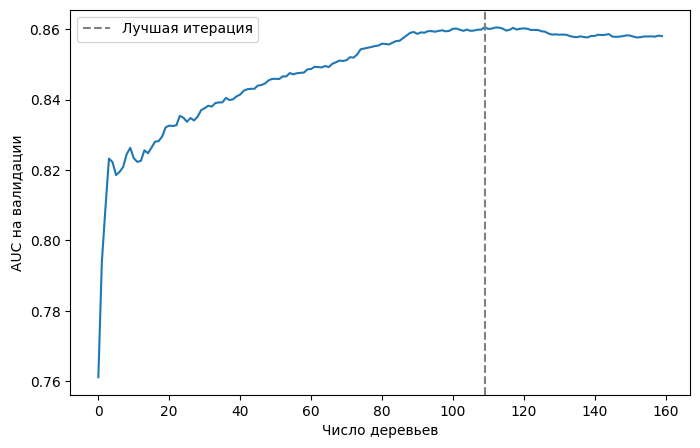

In [56]:
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size = 0.2, random_state = 123, stratify = y_train)

xgb_es = XGBClassifier(
    n_estimators=2000,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric='auc',
    early_stopping_rounds=50,
    tree_method='hist',
    random_state=123,
    n_jobs=-1
)
xgb_es.fit(X_tr, y_tr, eval_set=[(X_val, y_val)], verbose=False)

print('Лучшая итерация:', xgb_es.best_iteration, 'из', xgb_es.n_estimators)
print('AUC на валидации:', xgb_es.best_score)
print('AUC на тесте:', roc_auc_score(y_test, xgb_es.predict_proba(X_test)[:, 1]))

plt.figure(figsize=(8, 5))
plt.plot(xgb_es.evals_result()['validation_0']['auc'])
plt.axvline(xgb_es.best_iteration, color='gray', ls='--', label='Лучшая итерация')
plt.xlabel('Число деревьев')
plt.ylabel('AUC на валидации')
plt.legend();

## 6. Важность признаков

Три библиотеки считают важность по-разному, поэтому числа на графиках ниже сравнивать напрямую нельзя:

- XGBoost: `gain` – средний выигрыш в функции потерь от разбиений по признаку;
- LightGBM: `split` – сколько раз признак использован в разбиениях;
- CatBoost: `PredictionValuesChange` – насколько в среднем меняется предсказание, если изменить признак.

Можно сравнить только ранжирование признаков. Вспомните также permutation importance с прошлого семинара: она не зависит от устройства модели.

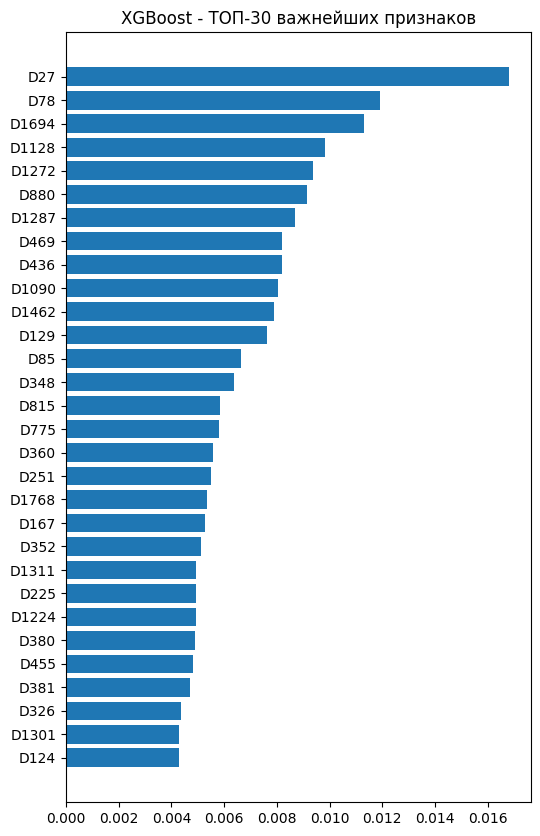

In [57]:
importance_xgb = xgb.feature_importances_
top_idx = np.argsort(importance_xgb)[-30:]
top_feature_names = [feature_names[i] for i in top_idx]
plt.figure(figsize=(6, 10))
plt.barh(range(30), importance_xgb[top_idx])
plt.yticks(range(30), top_feature_names)
plt.title("XGBoost - ТОП-30 важнейших признаков")
plt.show()

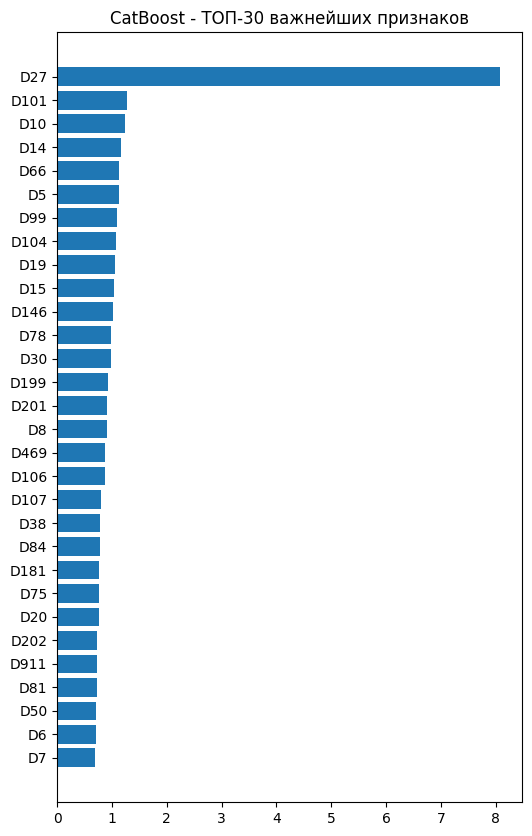

In [58]:
importance_cat = cat.get_feature_importance()
top_idx = np.argsort(importance_cat)[-30:]
top_feature_names = [feature_names[i] for i in top_idx]

plt.figure(figsize=(6, 10))
plt.barh(range(30), importance_cat[top_idx])
plt.yticks(range(30), top_feature_names)
plt.title("CatBoost - ТОП-30 важнейших признаков")
plt.show()

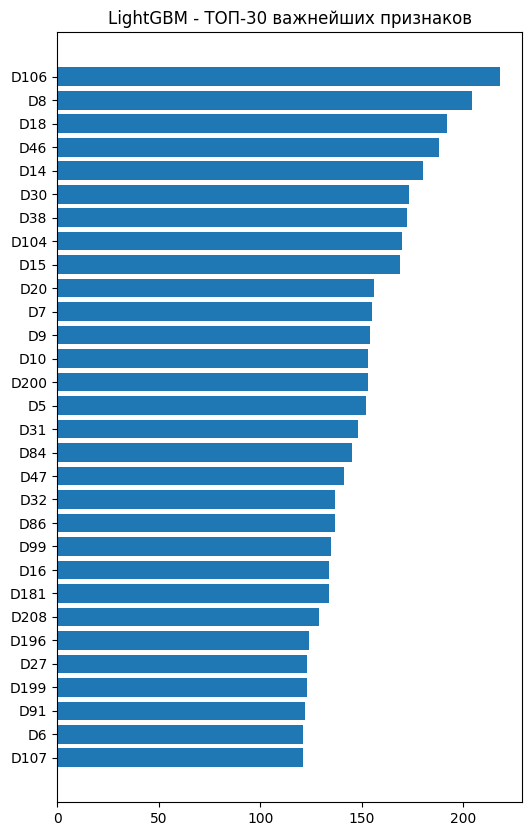

In [59]:
importance_lgbm = lgbm.feature_importances_
top_idx = np.argsort(importance_lgbm)[-30:]
top_feature_names = [feature_names[i] for i in top_idx]


plt.figure(figsize=(6, 10))
plt.barh(range(30), importance_lgbm[top_idx])
plt.yticks(range(30), top_feature_names)
plt.title("LightGBM - ТОП-30 важнейших признаков")
plt.show()

In [60]:
# Насколько совпадают топ-30 признаков у разных моделей
top = lambda imp: set(np.argsort(imp)[-30:])
tops = {'XGBoost': top(importance_xgb), 'CatBoost': top(importance_cat), 'LightGBM': top(importance_lgbm)}
names = list(tops)

for i in range(3):
    for j in range(i + 1, 3):
        print(f'{names[i]} и {names[j]}: общих признаков в топ-30: {len(tops[names[i]] & tops[names[j]])}')
print('Во всех трех:', len(set.intersection(*tops.values())))

XGBoost и CatBoost: общих признаков в топ-30: 3
XGBoost и LightGBM: общих признаков в топ-30: 1
CatBoost и LightGBM: общих признаков в топ-30: 18
Во всех трех: 1


### 6.1 SHAP

Встроенные важности отвечают на вопрос «какие признаки модель использует чаще или сильнее», но не говорят, **как** признак влияет на ответ: чем больше его значение, тем выше или ниже предсказание?

SHAP (SHapley Additive exPlanations) основан на значениях Шепли из теории кооперативных игр. Для каждого объекта предсказание раскладывается на вклады признаков:

$$
a(x) = \text{base value} + \sum_j \varphi_j(x),
$$

где base value – среднее предсказание модели, а $\varphi_j(x)$ – вклад признака $j$ на объекте $x$. Для бинарной классификации в бустинге $a(x)$ – это логит, поэтому и вклады измеряются в логитах, а не в вероятностях.

**Как читать график `summary_plot`:** каждая точка – один объект; строки упорядочены по среднему $|\varphi_j|$; положение точки по горизонтали – вклад признака (правее нуля повышает вероятность класса 1, левее – понижает); цвет – значение признака (красный – большое, синий – малое).

In [61]:
!pip install -q shap

In [62]:
import shap

Посмотрим анализ для CatBoost

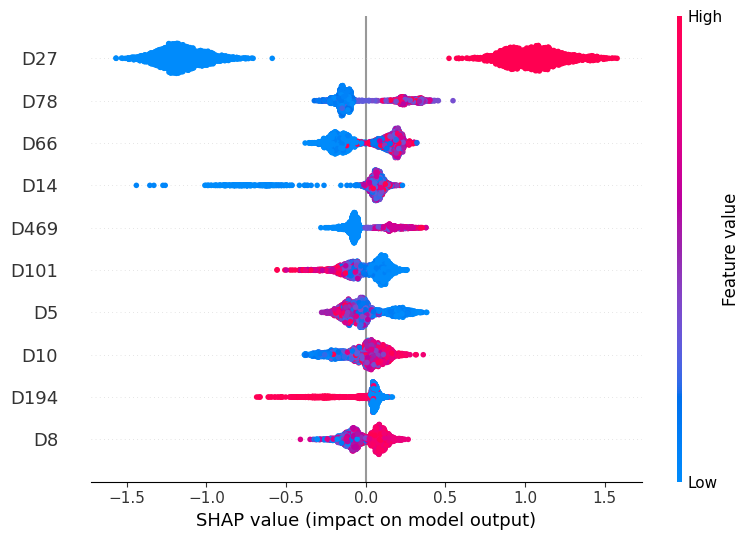

In [63]:
explainer_cat = shap.Explainer(cat)
shap_values_cat = explainer_cat.shap_values(X_train)

shap.summary_plot(
    shap_values_cat,
    X_train,
    max_display=10,
    rng=np.random.default_rng(123)
)

## 7. Подбор гиперпараметров

Модели бустинга очень мощные, но их качество сильно зависит от гиперпараметров: глубины деревьев, скорости обучения, числа итераций и других.
Если оставить параметры по умолчанию, модель может либо недообучиться, либо переобучиться и плохо работать на новых данных.

Подбор гиперпараметров помогает найти наиболее устойчивую и точную конфигурацию модели.

Познакомимся с тремя способами провести подбор гиперпараметров:
* RandomizedSearch на примере XGBoost,
* Optuna на примере LightGBM,
* Встроенный grid-search у CatBoost.

### 7.1. RandomizedSearch на примере XGBoost

Ссылка на документацию в [sklearn](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RandomizedSearchCV.html)

In [64]:
#время выполнения ~15 минут
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

xgb = XGBClassifier(
    objective='binary:logistic',
    eval_metric='auc',
    tree_method='hist',
    random_state=123,
)

param_dist_xgb = {
    "n_estimators": [200, 400, 600], # количество деревьев в ансамбле. Чем их больше, тем выше точность, но больше риск переобучения.
    "max_depth": [3, 5, 7, 9], # максимальная глубина деревьев. Глубокие деревья улавливают сложные зависимости, но могут переобучаться.
    "learning_rate": [0.01, 0.05, 0.1], # скорость обучения (шаг градиента). Низкая скорость делает обучение более "осторожным", требует больше деревьев.
    "subsample": [0.6, 0.8, 1.0], # доля тренировочных объектов, выбираемых случайно для каждого дерева. Уменьшает переобучение.
    "colsample_bytree": [0.6, 0.8, 1.0] # доля признаков, выбираемых случайно для каждого дерева. Также борется с переобучением.
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=123)

search_xgb = RandomizedSearchCV(
    xgb,
    param_distributions=param_dist_xgb,
    n_iter=20,
    cv=cv,
    scoring='roc_auc',
    verbose=1,
    random_state=123
)

search_xgb.fit(X_train, y_train)

best_xgb = search_xgb.best_estimator_
pred_xgb = best_xgb.predict_proba(X_test)[:, 1]
auc_xgb = roc_auc_score(y_test, pred_xgb)

print(f'XGBoost: лучший AUC на CV: {search_xgb.best_score_}')
print(f'XGBoost: AUC на тесте: {auc_xgb}')
print(f'Лучшие параметры: {search_xgb.best_params_}')


Fitting 3 folds for each of 20 candidates, totalling 60 fits
XGBoost: лучший AUC на CV: 0.8630094945477375
XGBoost: AUC на тесте: 0.8785095750362402
Лучшие параметры: {'subsample': 0.6, 'n_estimators': 600, 'max_depth': 7, 'learning_rate': 0.01, 'colsample_bytree': 1.0}


Проверьте, не лежит ли какой-то из лучших параметров на краю сетки (в нашем запуске так были `learning_rate=0.01` и `n_estimators=600`). Тогда оптимум может быть за пределами сетки, и ее нужно расширить, как мы делали с $C$ в логистической регрессии.

### 7.2. Optuna на примере LightGBM

Ссылка на [документацию](https://optuna.readthedocs.io/en/stable/)

In [65]:
!pip install optuna -q

In [66]:
# время выполнения ~ 7 минут
import optuna
from sklearn.model_selection import cross_val_score

optuna.logging.set_verbosity(optuna.logging.WARNING)  # не печатать каждую попытку

def objective_lgb(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 200, 800), # количество деревьев. Больше — лучше точно описывает данные, но риск переобучения выше.
        "num_leaves": trial.suggest_int("num_leaves", 16, 128), # максимальное число листьев в дереве LightGBM. Основной параметр, отвечающий за сложность модели.
        "max_depth": trial.suggest_int("max_depth", 3, 12), # ограничение глубины дерева. Нужно, чтобы не дать num_leaves разрастись слишком сильно.
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2, log=True), # скорость обучения. Низкие значения делают обучение более устойчивым.
        "subsample": trial.suggest_float("subsample", 0.6, 1.0), # доля обучающей выборки, используемая для каждого дерева. Помогает бороться с переобучением.
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0), # доля признаков, которая случайно выбирается при построении каждого дерева.
        "min_child_samples": trial.suggest_int("min_child_samples", 10, 50), # минимальное число объектов в листе. Увеличение этого параметра уменьшает вариативность и снижает переобучение.
        "subsample_freq": 1,  # без него subsample игнорируется
        "random_state": 123,
        "verbose": -1
    }

    model = LGBMClassifier(**params)

    scores = cross_val_score(
        model,
        X_train, y_train,
        cv=cv,  # те же фолды, что и у XGBoost
        scoring="roc_auc",
    )

    return scores.mean()

study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=123))
study.optimize(objective_lgb, n_trials=30)

print(f'LightGBM: лучший AUC на CV: {study.best_value}')
print(f'Лучшие параметры LightGBM: {study.best_params}')

best_lgb = LGBMClassifier(**study.best_params, subsample_freq=1, random_state=123, verbose=-1)
best_lgb.fit(X_train, y_train)
pred_lgb = best_lgb.predict_proba(X_test)[:, 1]
auc_lgb = roc_auc_score(y_test, pred_lgb)

print(f'LightGBM: AUC на тесте: {auc_lgb}')


LightGBM: лучший AUC на CV: 0.8637057146164125
Лучшие параметры LightGBM: {'n_estimators': 390, 'num_leaves': 62, 'max_depth': 11, 'learning_rate': 0.02117629327422143, 'subsample': 0.7932137057050818, 'colsample_bytree': 0.994223914244282, 'min_child_samples': 31}
LightGBM: AUC на тесте: 0.880013224485644


### 7.3. Встроенный grid-search у CatBoost

In [67]:
# самая долгая ячейка раздела: 18 конфигураций, каждая обучается на 80% обучающей выборки
cat = CatBoostClassifier(
    loss_function="Logloss",
    eval_metric="AUC",
    random_seed=123,
    logging_level="Silent"
)

param_grid_cat = {
    "depth": [4, 6, 8],
    "learning_rate": [0.03, 0.1],
    "iterations": [300, 500, 800]
}

grid_result = cat.grid_search(
    param_grid_cat,
    X=X_train,
    y=y_train,
    cv=3,
    shuffle=True,
    partition_random_seed=123,
    verbose=False
)

# Как работает grid_search: параметры сравниваются по одному разбиению train/validation (80/20),
# затем для лучших параметров считается 3-fold CV, и модель cat дообучается на всей X_train.
# Максимум по итерациям слегка оптимистичен.
auc_cv_cat = max(grid_result["cv_results"]["test-AUC-mean"])

print(f'CatBoost: AUC на CV для лучших параметров: {auc_cv_cat}')
print(f'Лучшие параметры CatBoost: {grid_result["params"]}')

pred_cat = cat.predict_proba(X_test)[:, 1]
auc_cat = roc_auc_score(y_test, pred_cat)

print(f'CatBoost: AUC на тесте: {auc_cat}')

Metric AUC is not calculated on train by default. To calculate this metric on train, add hints=skip_train~false to metric parameters.
Metric AUC is not calculated on train by default. To calculate this metric on train, add hints=skip_train~false to metric parameters.
Metric AUC is not calculated on train by default. To calculate this metric on train, add hints=skip_train~false to metric parameters.
Metric AUC is not calculated on train by default. To calculate this metric on train, add hints=skip_train~false to metric parameters.
Metric AUC is not calculated on train by default. To calculate this metric on train, add hints=skip_train~false to metric parameters.
Metric AUC is not calculated on train by default. To calculate this metric on train, add hints=skip_train~false to metric parameters.
Metric AUC is not calculated on train by default. To calculate this metric on train, add hints=skip_train~false to metric parameters.
Metric AUC is not calculated on train by default. To calculate

In [68]:
results = pd.DataFrame({
    "model": ["XGBoost", "CatBoost", "LightGBM"],
    "auc_cv": [search_xgb.best_score_, auc_cv_cat, study.best_value],
    "auc_test": [auc_xgb, auc_cat, auc_lgb]
})

display(results.sort_values("auc_test", ascending=False))

,model,auc_cv,auc_test
1,CatBoost,0.862317,0.881456
2,LightGBM,0.863706,0.880013
0,XGBoost,0.863009,0.878510


Как читать таблицу:

- у XGBoost и LightGBM фолды одинаковые, у CatBoost свои, поэтому `auc_cv` CatBoost нельзя сравнивать с остальными напрямую;
- сравните `auc_cv` и `auc_test`: на тесте модели обучены на всей обучающей выборке, а при CV только на 2/3 ее, поэтому AUC на тесте обычно выше;
- сравните результаты подбора с результатами из раздела 5: улучшение на CV не всегда видно на тесте, а различия между моделями лежат в пределах шума.

## 8. Выводы

1. Градиентный бустинг строит композицию последовательно: каждая новая модель обучается на антиградиенте функции потерь в точке ответов уже построенной композиции. Для $MSE$ это остатки.
2. Бустинг снижает смещение, поэтому базовые модели берут простые (неглубокие деревья), шаг делают небольшим, а число деревьев подбирают по валидации (ранняя остановка).
3. Бустинг с параметрами по умолчанию не обязан побеждать случайный лес. Хорошо настроенный бустинг обычно не хуже, но на нашем датасете различия между моделями лежат в пределах шума.
4. XGBoost, LightGBM и CatBoost отличаются устройством дерева, обработкой категориальных признаков и скоростью. Выбирают по данным: много категорий – CatBoost, большие данные и скорость – LightGBM.
5. При подборе гиперпараметров проверяйте, не лежит ли оптимум на краю сетки, и сравнивайте модели на одних и тех же фолдах.
6. Встроенные важности разных библиотек измеряются в разных единицах. SHAP показывает еще и направление влияния признака.